# Join of the dastasets

In [61]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut

hd_df = pd.read_csv("../../data/processed/hd.csv")
lab_events_df = pd.read_csv("../../data/processed/lab_events.csv")
micro_bio_df = pd.read_csv("../../data/processed/microbio.csv")
procedures_df = pd.read_csv("../../data/processed/procedure_code_summary.csv")

# Make the join between processed datasets

joined_df = pd.merge(hd_df, lab_events_df, on='hadm_id', how='left', suffixes=('_hd', '_le'))

joined_df = pd.merge(
    joined_df,
    micro_bio_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_micro')
)

joined_df = pd.merge(
    joined_df,
    procedures_df,
    on=['subject_id', 'hadm_id'],
    how='left',
    suffixes=('_joined', '_proc')
)

# Drop ALL duplicate rows (keeps only unique rows)
joined_df = joined_df.drop_duplicates().reset_index(drop=True)
#joined_df

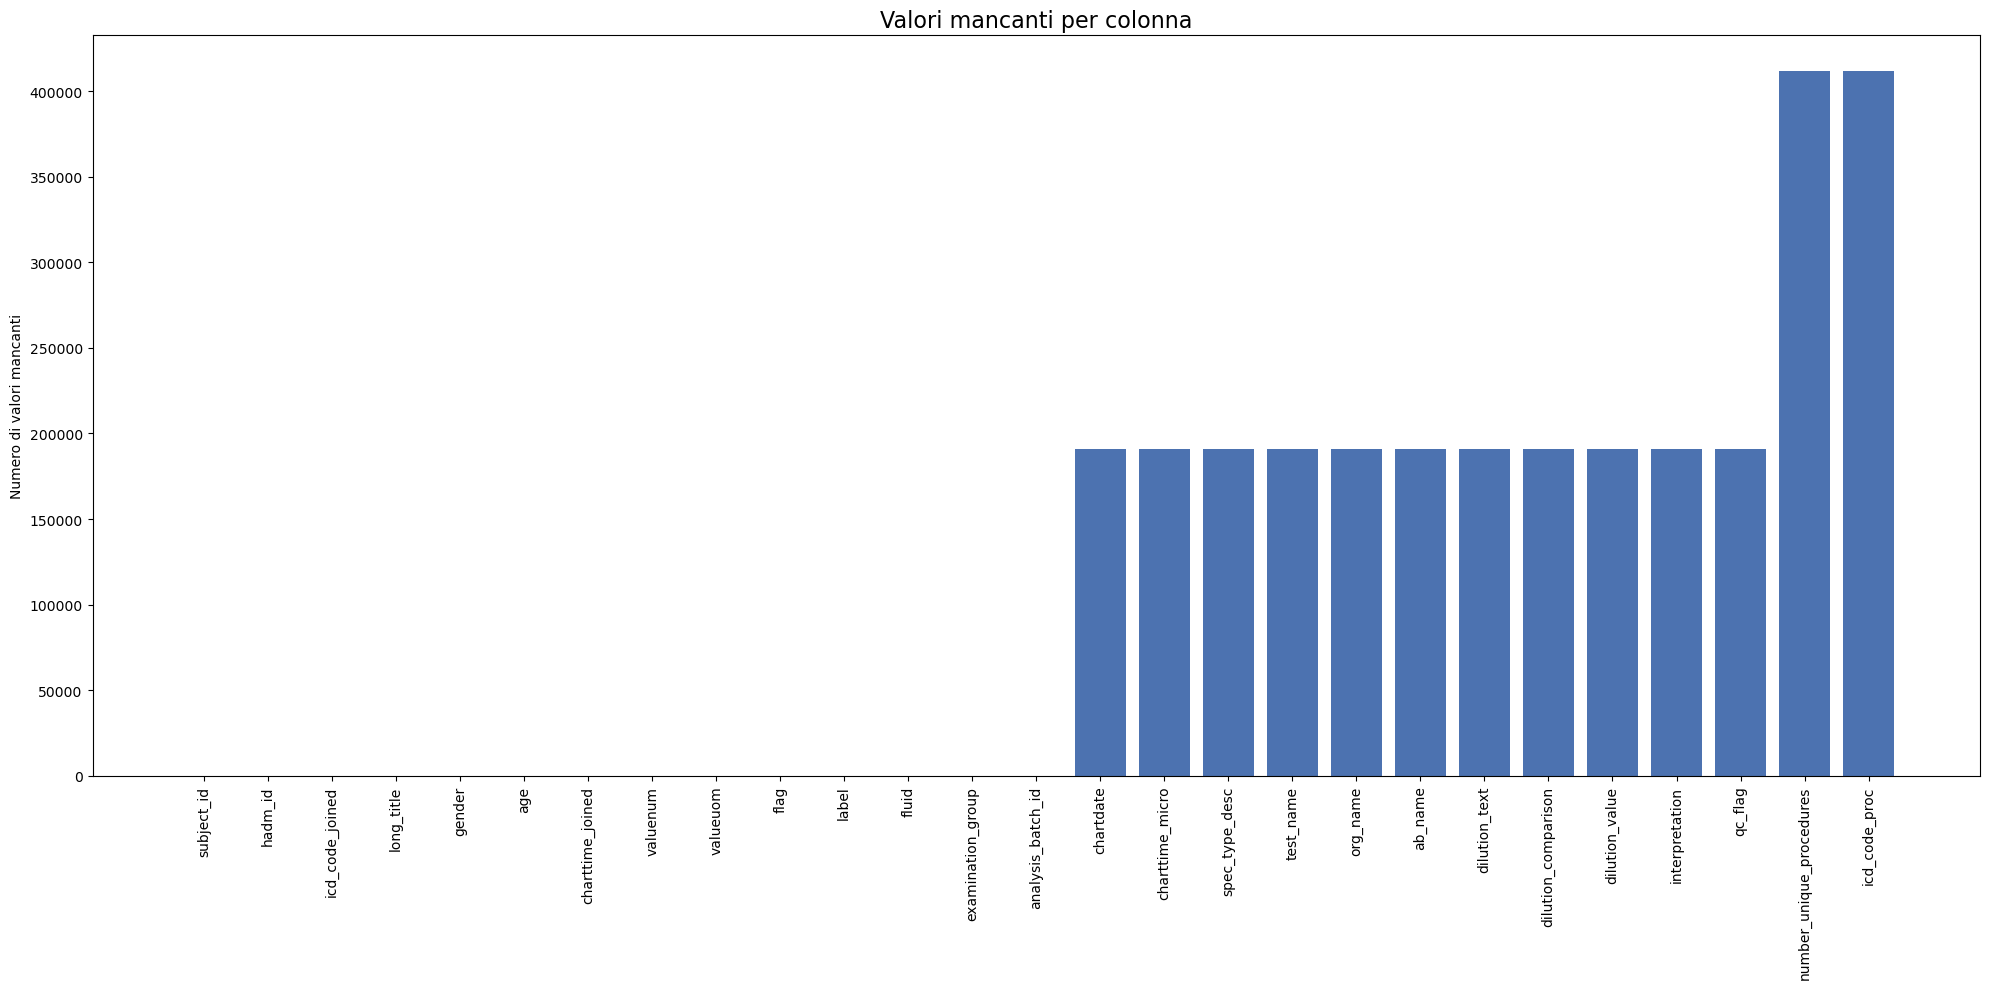

In [62]:

plt.figure(figsize=(20,10))

# Conteggio dei NaN per colonna
missing_counts = joined_df.isnull().sum()

# Barplot
plt.bar(missing_counts.index, missing_counts.values, color="#4c72b0")

plt.title("Valori mancanti per colonna", fontsize=16)
plt.ylabel("Numero di valori mancanti")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [63]:


def count_null_entries(df):
    """
    Conta quanti valori nulli (NaN) ci sono per riga
    e restituisce la distribuzione in percentuale.
    """
    # Conta i NaN per ogni riga
    null_counts = df.isnull().sum(axis=1)

    # Distribuzione: quante righe hanno 0, 1, 2... NaN
    null_percentage = null_counts.value_counts().sort_index() / len(df) * 100

    # Restituisce un dataframe riassuntivo
    return null_percentage.reset_index().rename(
        columns={'index': 'Numero di valori null per riga',
                 0: 'Percentuale righe null'}
    )

# Uso sul tuo dataset
count_null_entries(joined_df)



,Numero di valori null per riga,count
0,0,87.881370
1,2,7.802808
2,8,0.000068
3,11,2.821184
4,13,1.494322
5,19,0.000068
6,21,0.000181


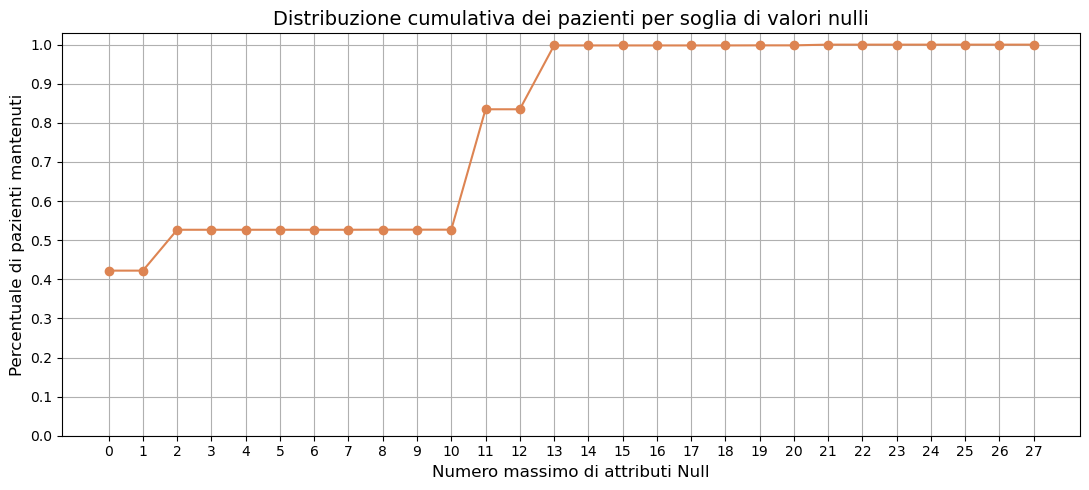

In [64]:


# Dizionario per salvare la percentuale cumulativa di pazienti
temp_pazienti = {}

# Totale pazienti unici nel dataset
totale_pazienti = joined_df["subject_id"].nunique()

# Loop su tutte le soglie da 0 a numero di colonne
for threshold in range(0, len(joined_df.columns)+1):
    # Maschera: righe con al massimo 'threshold' valori nulli
    mask = (joined_df.isnull().sum(axis=1)) <= threshold

    # Pazienti unici che rimarrebbero
    pazienti_mantenuti = joined_df[mask]["subject_id"].nunique()

    # Percentuale di pazienti mantenuti
    temp_pazienti[threshold] = pazienti_mantenuti / totale_pazienti

# Plot
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(list(temp_pazienti.keys()), list(temp_pazienti.values()), marker='o', color="#dd8452")

# Etichette e griglia
ax.set_xticks(range(0, len(joined_df.columns)+1, 1))
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.grid(True)
ax.set_xlabel("Numero massimo di attributi Null", fontsize=12)
ax.set_ylabel("Percentuale di pazienti mantenuti", fontsize=12)
ax.set_title("Distribuzione cumulativa dei pazienti per soglia di valori nulli", fontsize=14)
plt.tight_layout()
plt.show()


In [65]:
# Maschera: righe con più di 13 valori nulli DA SCEGLIERE CHE VALORE METTERE
mask_drop = joined_df.isnull().sum(axis=1) > 13

# Righe che verrebbero eliminate
rows_dropped = joined_df[mask_drop]

# Conteggio dei pazienti persi
num_pazienti_persi = rows_dropped["subject_id"].nunique()

# Percentuale sul totale
percentuale_persi = num_pazienti_persi /joined_df["subject_id"].nunique() * 100

print(f"Pazienti persi: {num_pazienti_persi} ({percentuale_persi:.2f}%)")


Pazienti persi: 11 (0.25%)


In [66]:
def drop_rows_with_nulls(df, threshold, ignore_cols=[]):
    """
    Elimina le righe che hanno più di 'threshold' valori nulli,
    ignorando le colonne specificate in 'ignore_cols'.
    """
    cols_to_check = [col for col in df.columns if col not in ignore_cols]
    min_non_nulls = len(cols_to_check) - threshold
    df_cleaned = df.dropna(thresh=min_non_nulls, subset=cols_to_check)
    return df_cleaned
joined_df = drop_rows_with_nulls(joined_df, threshold=13)

In [67]:
#Filling the missing values for those who did not have a lab event done
joined_df['valuenum'] = joined_df['valuenum'].fillna(value = -1)
joined_df['valueuom'] = joined_df['valueuom'].fillna(value = "NO_UOM")
joined_df['flag'] = joined_df['flag'].fillna(value = -1)
joined_df['label'] = joined_df['label'].fillna(value = "NO_LAB_LABEL")
joined_df['fluid'] = joined_df['fluid'].fillna(value = "NO_FLUID")
joined_df['examination_group'] = joined_df['examination_group'].fillna(value = "NO_EXAM_GROUP")
joined_df['analysis_batch_id'] = joined_df['analysis_batch_id'].fillna(value = "NO_BATCH_ID")

# Filling the missing values for those who did not have any procedure done
joined_df['number_unique_procedures'] = joined_df['number_unique_procedures'].fillna(value = 0)
joined_df['icd_code_proc'] = joined_df['icd_code_proc'].fillna(value = "NO_PROCEDURES")

joined_df

,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
1,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
2,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,0.02,ng/mL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
3,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,2.20,u,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,73.00,sec,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430901,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,200.00,mg/dL,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430902,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES
4430903,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NO_PROCEDURES


In [68]:
# Filling the missing values for those who did not have a microbio test done
joined_df['spec_type_desc'] = joined_df['spec_type_desc'].fillna(value = "NO_MICROBIO")
joined_df

#If NO_MICROBIO, fill the microbio_test fields 
micro_bio_cols = ['org_name', 'ab_name', 'dilution_text','dilution_comparison','dilution_value', 'interpretation', 'qc_flag']

micro_bio_mask = joined_df['spec_type_desc'] == "NO_MICROBIO"

#Fill orgname with NOT_ORG_DETECTED
joined_df.loc[micro_bio_mask, 'org_name'] = joined_df.loc[micro_bio_mask, 'org_name'].fillna(value = "NO_ORG_DETECTED")

#Fill test_name with NO_TEST_DONE
joined_df.loc[micro_bio_mask, 'test_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_TEST_DONE")

# Fill ab_name with NO_AB_DETECTED
joined_df.loc[micro_bio_mask, 'ab_name'] = joined_df.loc[micro_bio_mask, 'ab_name'].fillna(value = "NO_AB_DETECTED")

#Fill dilution_text with "-1"
joined_df.loc[micro_bio_mask, 'dilution_text'] = joined_df.loc[micro_bio_mask, 'dilution_text'].fillna(value = "-1")

#Fill dilution_comparison with "="
joined_df.loc[micro_bio_mask, 'dilution_comparison'] = joined_df.loc[micro_bio_mask, 'dilution_comparison'].fillna(value = "=")

#Fill dilution_value with -1
joined_df.loc[micro_bio_mask, 'dilution_value'] = joined_df.loc[micro_bio_mask, 'dilution_value'].fillna(value = -1)

#Fill interpretation with NOT_INTERPRETATION
joined_df.loc[micro_bio_mask, 'interpretation'] = joined_df.loc[micro_bio_mask, 'interpretation'].fillna(value = "NO_INTERPRETATION")

#Fill qc_flag with NOT_QC_FLAG
joined_df.loc[micro_bio_mask, 'qc_flag'] = joined_df.loc[micro_bio_mask, 'qc_flag'].fillna(value = "NO_QC_FLAG")

joined_df


,subject_id,hadm_id,icd_code_joined,long_title,gender,age,charttime_joined,valuenum,valueuom,flag,...,test_name,org_name,ab_name,dilution_text,dilution_comparison,dilution_value,interpretation,qc_flag,number_unique_procedures,icd_code_proc
0,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,198.00,IU/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
1,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,5.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
2,10000980,29654838,I50,Heart failure,F,75.0,2188-01-04 23:43:00,0.02,ng/mL,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
3,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,2.20,u,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4,10000980,29654838,I50,Heart failure,F,75.0,2188-01-05 06:56:00,73.00,sec,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430900,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,2.00,ng/mL,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430901,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,200.00,mg/dL,1.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430902,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,3.90,mEq/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES
4430903,19998600,21593455,I35,Nonrheumatic aortic valve disorders,M,83.0,2155-11-27 10:00:00,141.00,mEq/L,0.0,...,NO_TEST_DONE,NO_ORG_DETECTED,NO_AB_DETECTED,-1,=,-1.0,NO_INTERPRETATION,NO_QC_FLAG,0.0,NO_PROCEDURES


## Correlation between the cols

In [69]:
# Getting the correlations
numeric_cols = du.get_numeric_cols(joined_df)
# Pearson correlation
joined_df[numeric_cols].corr("pearson")

,age,valuenum,flag,dilution_value,number_unique_procedures
age,1.000000,-0.010701,0.031146,0.066692,-0.120179
valuenum,-0.010701,1.000000,0.019265,-0.004554,0.021134
flag,0.031146,0.019265,1.000000,0.007255,0.084397
dilution_value,0.066692,-0.004554,0.007255,1.000000,-0.042185
number_unique_procedures,-0.120179,0.021134,0.084397,-0.042185,1.000000


In [70]:
# Kendall correlation
joined_df[numeric_cols].corr("kendall")

,age,valuenum,flag,dilution_value,number_unique_procedures
age,1.000000,0.003346,0.028782,0.123835,-0.115999
valuenum,0.003346,1.000000,-0.051440,0.000082,0.005791
flag,0.028782,-0.051440,1.000000,0.016447,0.067926
dilution_value,0.123835,0.000082,0.016447,1.000000,0.028365
number_unique_procedures,-0.115999,0.005791,0.067926,0.028365,1.000000


In [71]:
# Spearman correlation
joined_df[numeric_cols].corr("spearman")

,age,valuenum,flag,dilution_value,number_unique_procedures
age,1.000000,0.004608,0.032932,0.149815,-0.170569
valuenum,0.004608,1.000000,-0.062659,0.000114,0.008298
flag,0.032932,-0.062659,1.000000,0.017497,0.080650
dilution_value,0.149815,0.000114,0.017497,1.000000,0.035639
number_unique_procedures,-0.170569,0.008298,0.080650,0.035639,1.000000


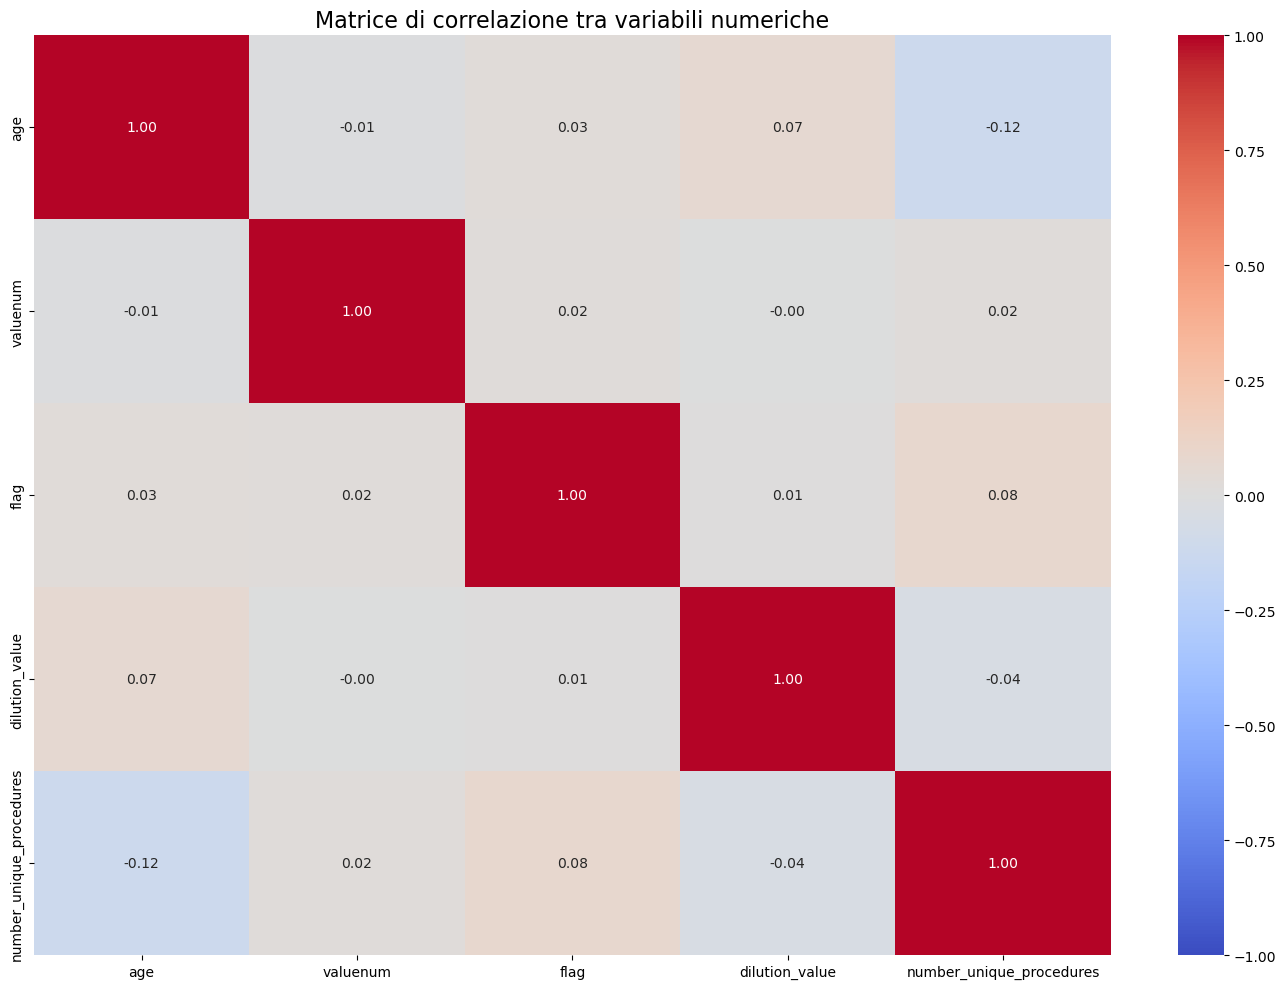

In [72]:


# Seleziona solo le colonne numeriche
df_num = joined_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = df_num.corr()

# Plot della heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice di correlazione tra variabili numeriche", fontsize=16)
plt.tight_layout()
plt.show()


# Feature creation

In [106]:
# Creating the new features representing the profiles of the patients
#Taking the common attributes (subject_id,hadm_id, gender, age, ICD)
profile_cols = ['subject_id', 'hadm_id', 'gender', 'age', 'icd_code_joined']
profile_df = joined_df[profile_cols].drop_duplicates().reset_index(drop=True)

# === LAB PROFILE FEATURES === #

#Creating the feature for the lab events, if "NO_LAB_LABEL" then count is 0
lab_event_counts = joined_df.groupby(['subject_id', 'hadm_id'])['label'].apply(lambda x: (x != "NO_LAB_LABEL").sum()).reset_index()
lab_event_counts = lab_event_counts.rename(columns={'label': 'lab_event_count'})

# Merge con il profilo paziente
profile_df = pd.merge(profile_df, lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['lab_event_count'] = profile_df['lab_event_count'].fillna(0)

# Creating the ratio of abnormal lab events to total lab events, if no lab events then ratio is 0
abnormal_lab_event_counts = joined_df[joined_df['flag'] == 1].groupby(['subject_id', 'hadm_id'])['flag'].count().reset_index()
abnormal_lab_event_counts = abnormal_lab_event_counts.rename(columns={'flag': 'abnormal_lab_event_count'})
profile_df = pd.merge(profile_df, abnormal_lab_event_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['abnormal_lab_event_count'] = profile_df['abnormal_lab_event_count'].fillna(0)

profile_df['abnormal_lab_event_ratio'] = profile_df.apply(
    lambda row: row['abnormal_lab_event_count'] / row['lab_event_count'] if row['lab_event_count'] > 0 else 0,
    axis=1
)
profile_df=profile_df.drop(columns=['abnormal_lab_event_count'])
# Creating the lab events density using the charttime
lab_event_times = joined_df[joined_df['label'] != "NO_LAB_LABEL"].groupby(['subject_id', 'hadm_id'])['charttime_joined'].agg(['min', 'max']).reset_index()
lab_event_times['lab_event_duration_days'] = (pd.to_datetime(lab_event_times['max']) - pd.to_datetime(lab_event_times['min'])).dt.days + 1
profile_df = pd.merge(profile_df, lab_event_times[['subject_id', 'hadm_id', 'lab_event_duration_days']], on=['subject_id', 'hadm_id'], how='left')
profile_df['lab_event_duration_days'] = profile_df['lab_event_duration_days'].fillna(1)
profile_df['lab_event_density'] = profile_df.apply(
    lambda row: row['lab_event_count'] / row['lab_event_duration_days'] if row['lab_event_duration_days'] > 0 else 0,
    axis=1
)

# === MICROBIO PROFILE FEATURES === #

#Counting the number of microbio tests done per subject_id and hadm_id, if "NO_MICROBIO" then count is 0
# Deduplicazione mirata sugli eventi microbiologici
icrobio_test_counts = joined_df[joined_df['spec_type_desc'] != "NO_MICROBIO"].groupby(['subject_id', 'hadm_id'])['spec_type_desc'].nunique().reset_index()
microbio_test_counts = microbio_test_counts.rename(columns={'spec_type_desc': 'microbio_test_count'})

# Merge nel profilo paziente
profile_df = pd.merge(profile_df, microbio_test_counts, on=['subject_id','hadm_id'], how='left')
profile_df['microbio_test_count'] = profile_df['microbio_test_count'].fillna(0)

# Counting the number of unique microorganisms detected per subject_id and hadm_id, if "NO_ORG_DETECTED" then count is 0
microbio_counts = joined_df[joined_df['org_name'] != "NO_ORG_DETECTED"].groupby(['subject_id', 'hadm_id'])['org_name'].nunique().reset_index()
microbio_counts = microbio_counts.rename(columns={'org_name': 'unique_microorganisms_count'})
profile_df = pd.merge(profile_df, microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_microorganisms_count'] = profile_df['unique_microorganisms_count'].fillna(0)

# Ratio of resistant microorganisms to total microorganisms detected, if intepretation is "NO_INTERPRETATION" then count is 0
resistant_microbio_counts = (
    joined_df[(joined_df["interpretation"] == "R") & (joined_df["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="resistant_microorganisms_count")
)
profile_df = pd.merge(profile_df, resistant_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['resistant_microorganisms_count'] = profile_df['resistant_microorganisms_count'].fillna(0)
profile_df['resistant_microorganism_ratio'] = profile_df.apply(
    lambda row: row['resistant_microorganisms_count'] / row['unique_microorganisms_count'] if row['unique_microorganisms_count'] > 0 else 0,
    axis=1
)
profile_df=profile_df.drop(columns=['resistant_microorganisms_count'])
# Ratio of intermediate microorganisms to total microorganisms detected, if intepretation is "NO_INTERPRETATION" then count is 0
intermediate_microbio_counts = (
    joined_df[(joined_df["interpretation"] == "I") & (joined_df["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="intermediate_microorganisms_count")
)

profile_df = pd.merge(profile_df, intermediate_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['intermediate_microorganisms_count'] = profile_df['intermediate_microorganisms_count'].fillna(0)
profile_df['intermediate_microorganism_ratio'] = profile_df.apply(
    lambda row: row['intermediate_microorganisms_count'] / row['unique_microorganisms_count'] if row['unique_microorganisms_count'] > 0 else 0,
    axis=1
)
profile_df=profile_df.drop(columns=['intermediate_microorganism_ratio'])
# Ratio of sensitive microorganisms to total microorganisms detected, if intepretation is "NO_INTERPRETATION" then count is 0
sensitive_microbio_counts = (
    joined_df[(joined_df["interpretation"] == "S") & (joined_df["org_name"] != "NO_ORG_DETECTED")]
    .drop_duplicates(subset=["subject_id", "hadm_id", "org_name"])
    .groupby(["subject_id", "hadm_id"])["org_name"]
    .nunique()
    .reset_index(name="sensitive_microorganisms_count")
)
profile_df = pd.merge(profile_df, sensitive_microbio_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['sensitive_microorganisms_count'] = profile_df['sensitive_microorganisms_count'].fillna(0)
profile_df['sensitive_microorganism_ratio'] = profile_df.apply(
    lambda row: row['sensitive_microorganisms_count'] / row['unique_microorganisms_count'] if row['unique_microorganisms_count'] > 0 else 0,
    axis=1
)
profile_df=profile_df.drop(columns=['sensitive_microorganism_ratio'])

# Creating the microbio test density using the charttime_microbio
microbio_test_times = joined_df[joined_df['spec_type_desc'] != "NO_MICROBIO"].groupby(['subject_id', 'hadm_id'])['charttime_micro'].agg(['min', 'max']).reset_index()
microbio_test_times['microbio_test_duration_days'] = (pd.to_datetime(microbio_test_times['max']) - pd.to_datetime(microbio_test_times['min'])).dt.days + 1
profile_df = pd.merge(profile_df, microbio_test_times[['subject_id', 'hadm_id', 'microbio_test_duration_days']], on=['subject_id', 'hadm_id'], how='left')
profile_df['microbio_test_duration_days'] = profile_df['microbio_test_duration_days'].fillna(1)
profile_df['microbio_test_density'] = profile_df.apply(
    lambda row: row['microbio_test_count'] / row['microbio_test_duration_days'] if row['microbio_test_duration_days'] > 0 else 0,
    axis=1
)

# === PROCEDURE PROFILE FEATURES === #
# Counting the number of unique procedures done per subject_id and hadm_id, if "NO_PROCEDURES" then count is 0
procedure_counts = joined_df[joined_df['icd_code_proc'] != "NO_PROCEDURES"].groupby(['subject_id', 'hadm_id'])['icd_code_proc'].nunique().reset_index()
procedure_counts = procedure_counts.rename(columns={'icd_code_proc': 'unique_procedures_count'})
profile_df = pd.merge(profile_df, procedure_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['unique_procedures_count'] = profile_df['unique_procedures_count'].fillna(0)

# Taking the total procedures codes per subject_id and hadm_id, if "NO_PROCEDURES" then "NO PROCEDURES"
total_procedure_counts = joined_df.groupby(['subject_id', 'hadm_id'])['number_unique_procedures'].max().reset_index()
total_procedure_counts = total_procedure_counts.rename(columns={'number_unique_procedures': 'total_procedures_count'})
profile_df = pd.merge(profile_df, total_procedure_counts, on=['subject_id', 'hadm_id'], how='left')
profile_df['total_procedures_count'] = profile_df['total_procedures_count'].fillna(0)
profile_df=profile_df.drop(columns=['unique_procedures_count'])

# == SOME INDICATORS ==
# Calcolo del massimo valore di glucosio per ogni paziente e ammissione
glucose_max = (
    joined_df[joined_df['label'] == "Glucose"]  # seleziona solo gli eventi di glucosio
    .groupby(['subject_id', 'hadm_id'])['valuenum']  # 'value' è la colonna con i risultati numerici
    .max()
    .reset_index(name='max_glucose')
)

# Merge con il profilo paziente
profile_df = pd.merge(profile_df, glucose_max, on=['subject_id', 'hadm_id'], how='left')
profile_df['max_glucose'] = profile_df['max_glucose'].fillna(0)

# Seleziona solo gli eventi di glucosio
glucose_events = joined_df[joined_df['label'] == "Glucose"].copy()

# Ordina per tempo
glucose_events['charttime_joined'] = pd.to_datetime(glucose_events['charttime_joined'])
glucose_events = glucose_events.sort_values(['subject_id', 'hadm_id', 'charttime_joined'])

# Calcola primo e ultimo valore per ogni paziente/ammissione
glucose_trend = glucose_events.groupby(['subject_id', 'hadm_id'])['valuenum'].agg(['first', 'last']).reset_index()

# Funzione per classificare il trend: 1 increase; -1 decrease; 0 stable
def classify_trend(row, tol=5):
    if row['last'] > row['first'] + tol:
        return "1"
    elif row['last'] < row['first'] - tol:
        return "-1"
    else:
        return "0"

# Applica la classificazione
glucose_trend['glucose_trend'] = glucose_trend.apply(classify_trend, axis=1)

# Merge con il profilo paziente
profile_df = pd.merge(profile_df, glucose_trend[['subject_id', 'hadm_id', 'glucose_trend']], 
                      on=['subject_id', 'hadm_id'], how='left')


# Se non ci sono valori di glucosio → -1
profile_df['glucose_trend'] = profile_df['glucose_trend'].fillna(-2)



# Removes all the counts columns used for calculations
#cols = profile_df.columns
#counts_cols = [col for col in cols if 'count' in col and col not in ['subject_id', 'hadm_id']]
#profile_df = profile_df.drop(columns=counts_cols)

# Remove duplicates (just in case)
profile_df = profile_df.drop_duplicates().reset_index(drop=True)


profile_df

,subject_id,hadm_id,gender,age,icd_code_joined,lab_event_count,abnormal_lab_event_ratio,lab_event_duration_days,lab_event_density,microbio_test_count,unique_microorganisms_count,resistant_microorganism_ratio,intermediate_microorganisms_count,sensitive_microorganisms_count,microbio_test_duration_days,microbio_test_density,total_procedures_count,max_glucose,glucose_trend
0,10000980,29654838,F,75.0,I50,45,0.400000,2.0,22.500000,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.0,200.0,1
1,10000980,26913865,F,75.0,I21,124,0.411290,6.0,20.666667,1.0,0.0,0.0,0.0,0.0,1.0,1.000000,7.0,200.0,0
2,10002013,24760295,F,69.0,I21,40,0.375000,2.0,20.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,2.0,200.0,0
3,10002155,23822395,F,69.0,I21,3312,0.384058,14.0,236.571429,4.0,0.0,0.0,0.0,0.0,9.0,0.444444,8.0,210.0,1
4,10004457,28723315,M,66.0,I35,21,0.285714,1.0,21.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.0,92.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848,19998596,24860241,F,71.0,I48,118,0.525424,6.0,19.666667,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.0,200.0,1
4849,19998597,23720781,F,57.0,I31,110,0.572727,6.0,18.333333,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.0,200.0,0
4850,19998598,26940500,F,69.0,I47,40,0.250000,1.0,40.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.0,200.0,-1
4851,19998599,20343031,M,59.0,I30,56,0.482143,2.0,28.000000,0.0,0.0,0.0,0.0,0.0,1.0,0.000000,0.0,200.0,0


# Visual exploration of the new features


In [107]:
profile_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4853 entries, 0 to 4852
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   subject_id                         4853 non-null   int64  
 1   hadm_id                            4853 non-null   int64  
 2   gender                             4853 non-null   object 
 3   age                                4853 non-null   float64
 4   icd_code_joined                    4853 non-null   object 
 5   lab_event_count                    4853 non-null   int64  
 6   abnormal_lab_event_ratio           4853 non-null   float64
 7   lab_event_duration_days            4853 non-null   float64
 8   lab_event_density                  4853 non-null   float64
 9   microbio_test_count                4853 non-null   float64
 10  unique_microorganisms_count        4853 non-null   float64
 11  resistant_microorganism_ratio      4853 non-null   float

In [108]:
# Conversione in stringa (più comune)
profile_df['subject_id'] = profile_df['subject_id'].astype(object)
profile_df['hadm_id'] = profile_df['hadm_id'].astype(object)
profile_df['glucose_trend']=profile_df['glucose_trend'].astype(float)

In [109]:
profile_df.describe()

,age,lab_event_count,abnormal_lab_event_ratio,lab_event_duration_days,lab_event_density,microbio_test_count,unique_microorganisms_count,resistant_microorganism_ratio,intermediate_microorganisms_count,sensitive_microorganisms_count,microbio_test_duration_days,microbio_test_density,total_procedures_count,max_glucose,glucose_trend
count,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000,4853.000000
mean,70.287039,913.021018,0.376575,5.316711,90.684984,1.092314,0.181743,0.039852,0.020400,0.095611,2.011127,0.600324,2.890583,185.101793,-0.120750
std,9.320152,4490.215916,0.144531,4.659339,194.784571,1.500525,0.556329,0.185571,0.142828,0.354466,3.027403,0.818873,2.938954,42.814256,0.658078
min,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,-2.000000
25%,66.000000,57.000000,0.277778,2.000000,20.875000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,200.000000,-1.000000
50%,70.000000,110.000000,0.377551,4.000000,27.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.166667,2.000000,200.000000,0.000000
75%,75.000000,399.000000,0.481651,7.000000,69.857143,2.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,5.000000,200.000000,0.000000
max,95.000000,142144.000000,1.000000,53.000000,4268.800000,15.000000,9.000000,1.000000,2.000000,4.000000,46.000000,7.000000,21.000000,210.000000,1.000000


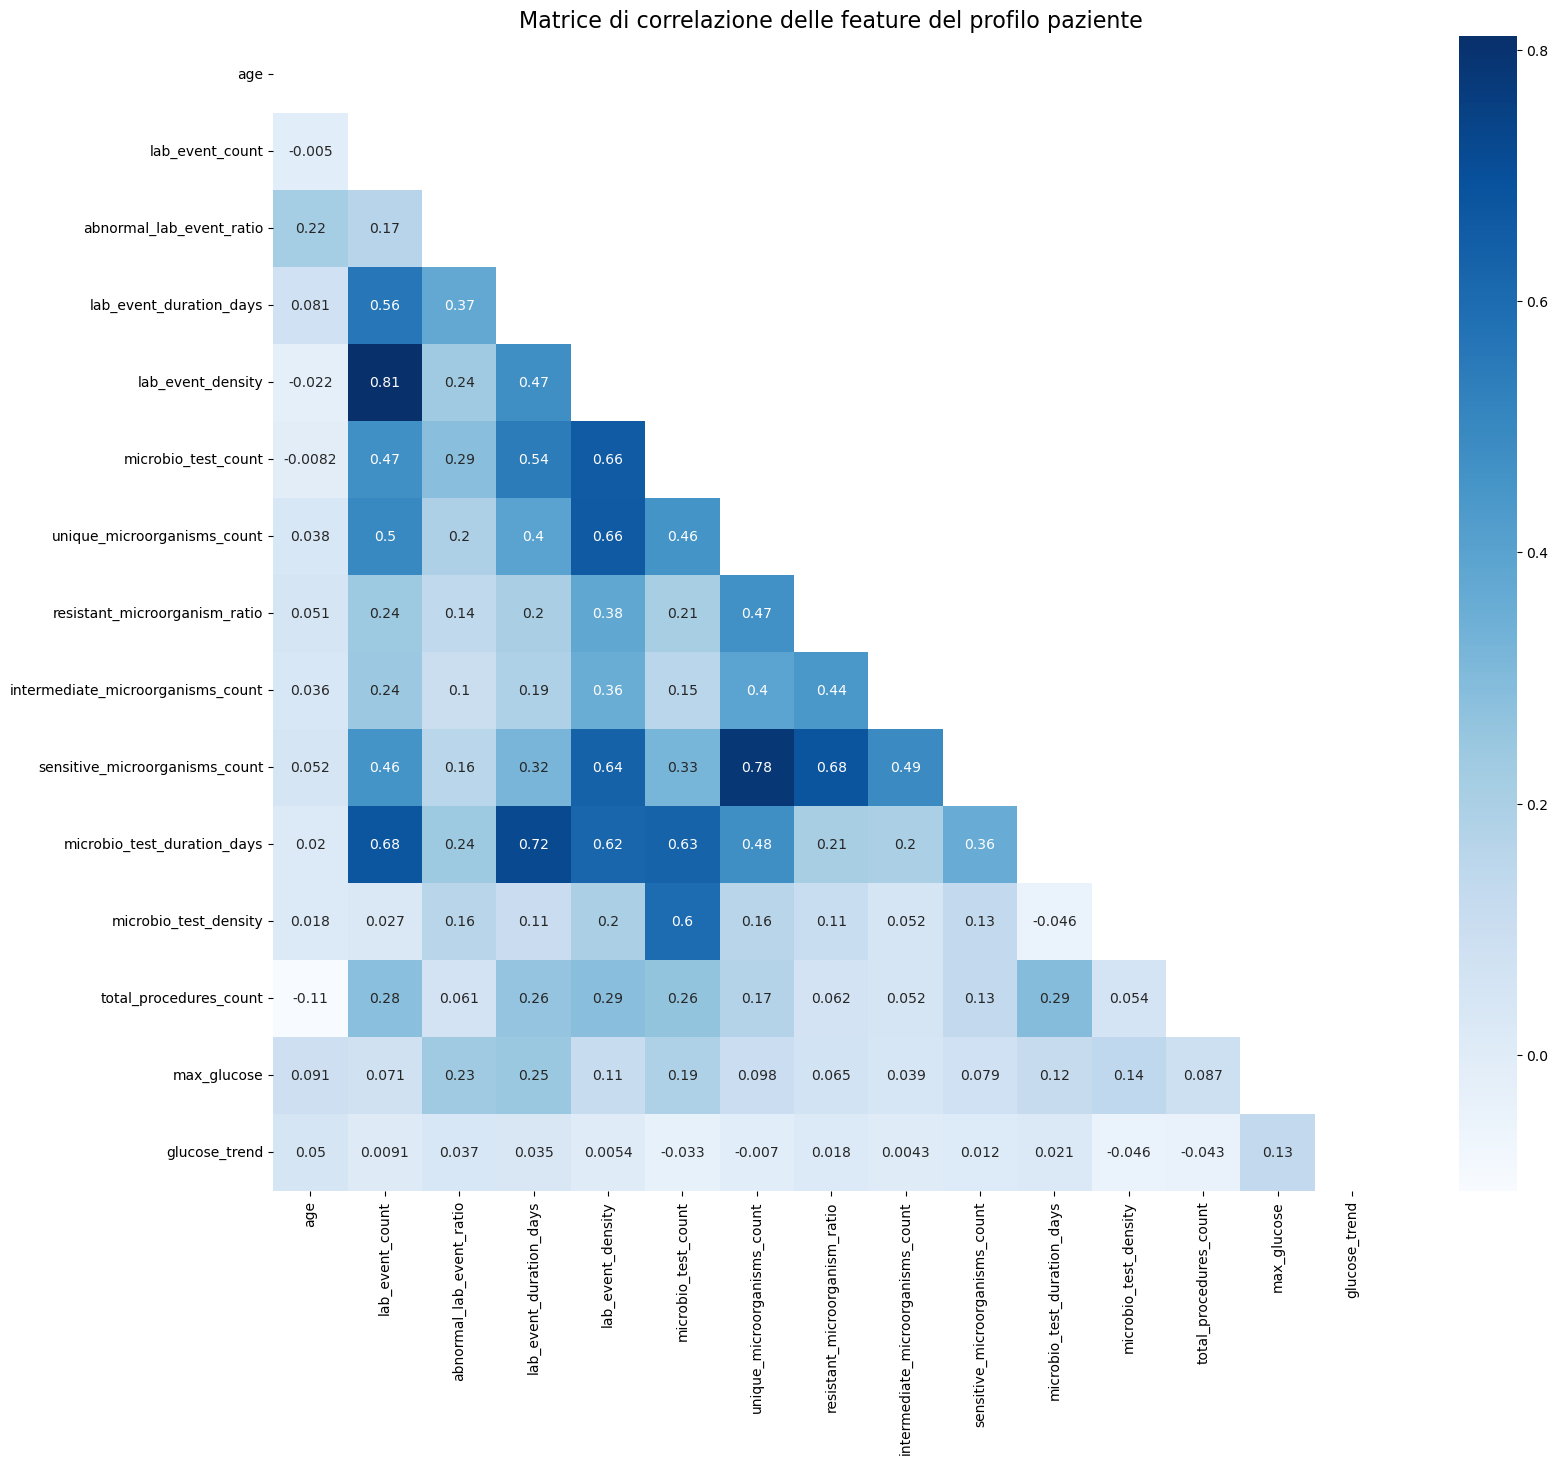

In [110]:
#correletion
# Seleziona solo le colonne numeriche dal profilo paziente
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Calcola la matrice di correlazione
corr_matrix = profile_num.corr()

# Maschera triangolare superiore
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot
plt.figure(figsize=(18,15))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', mask=mask)
plt.title("Matrice di correlazione delle feature del profilo paziente", fontsize=16)
plt.show()

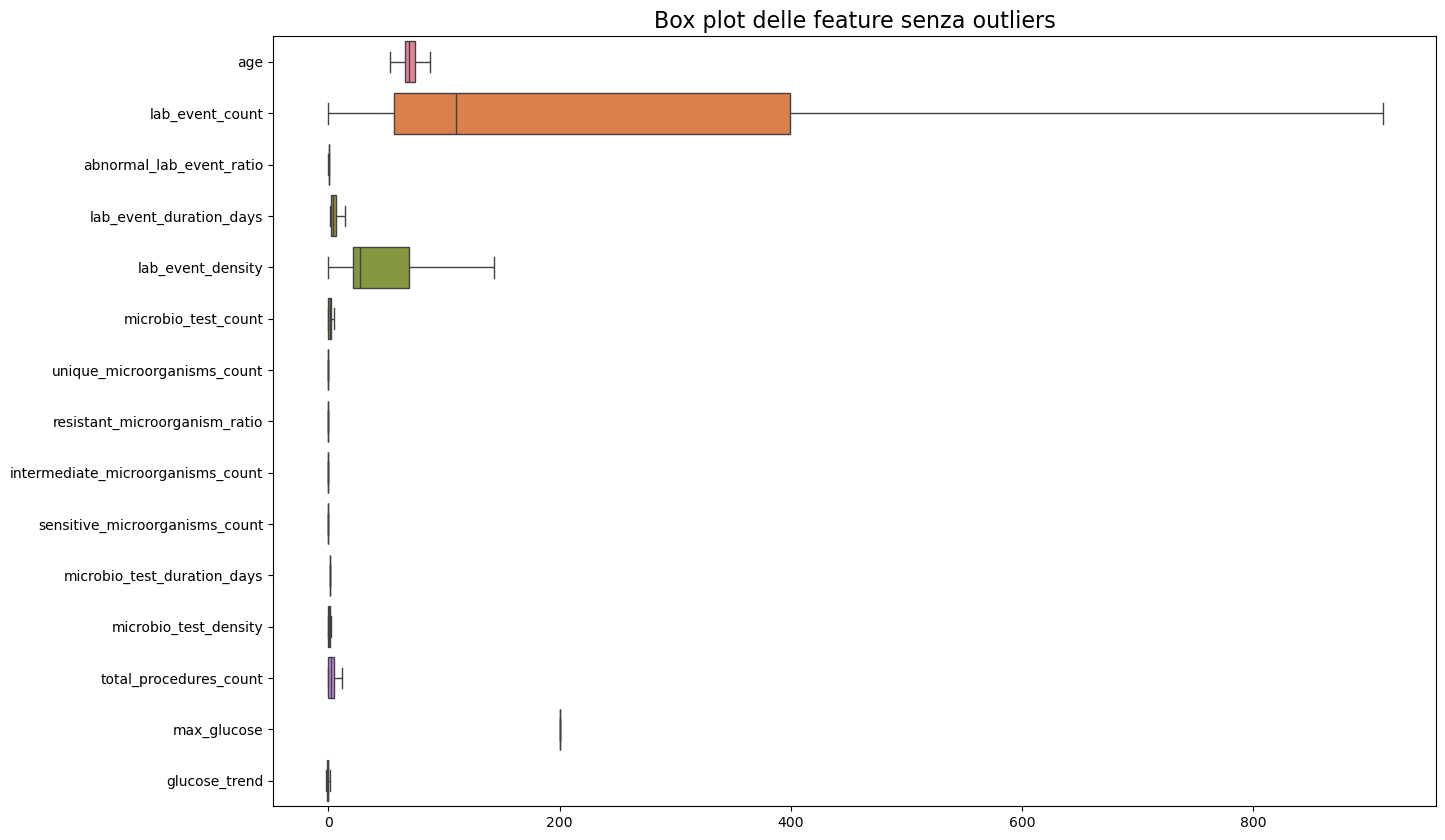

In [111]:
plt.figure(figsize=(15,10))
sns.boxplot(data=profile_num, orient="h", showfliers=False)
plt.title("Box plot delle feature senza outliers", fontsize=16)
plt.show()

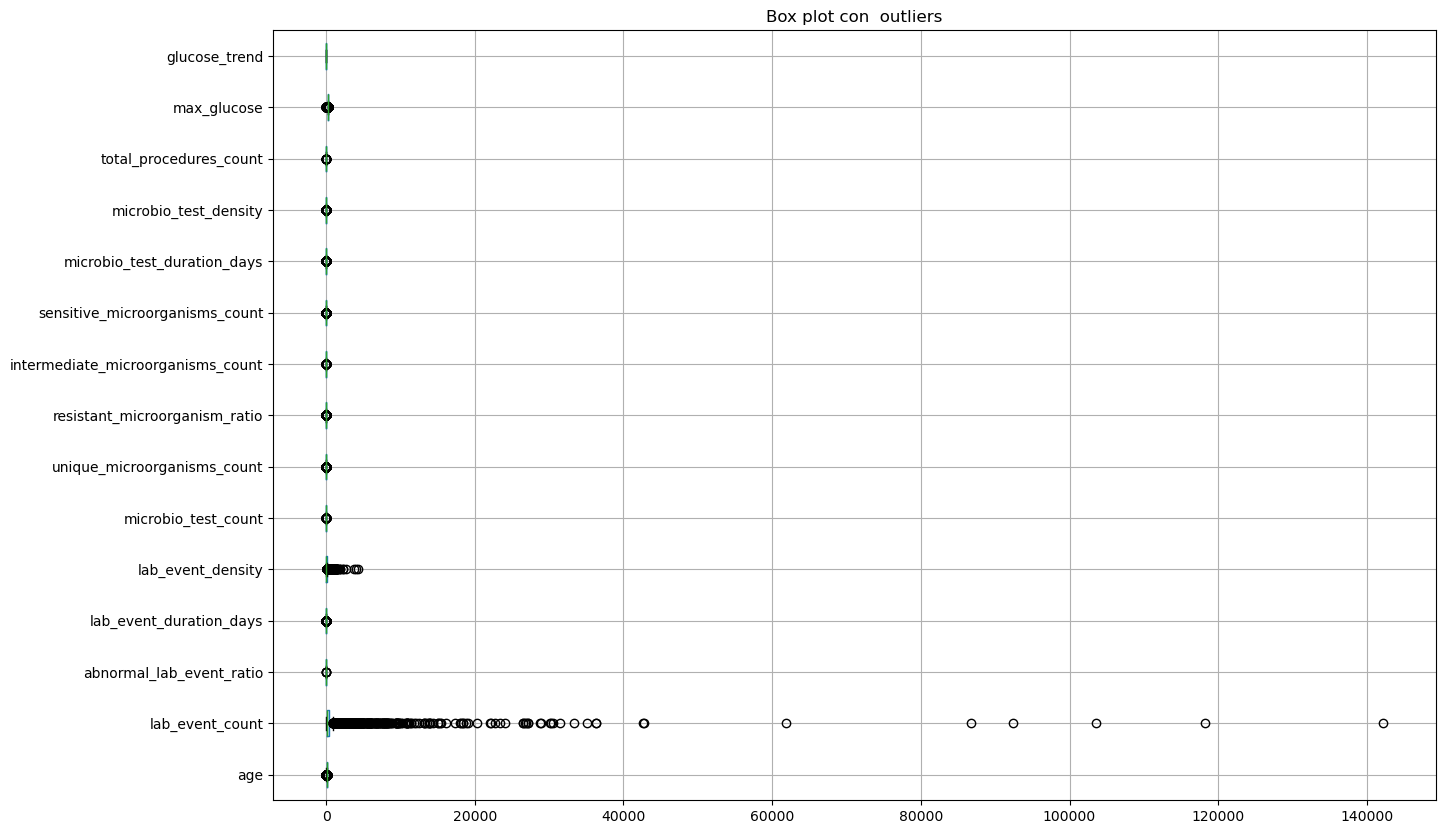

In [112]:
profile_num.boxplot(vert=False, figsize=(15, 10), showfliers=True)
plt.title('Box plot con  outliers')
plt.show()

## Visual exploration
The following plots give a quick overview of age distribution in the cohort, the tests with the highest abnormal rates, and how resistance relates to antibiotic coverage.

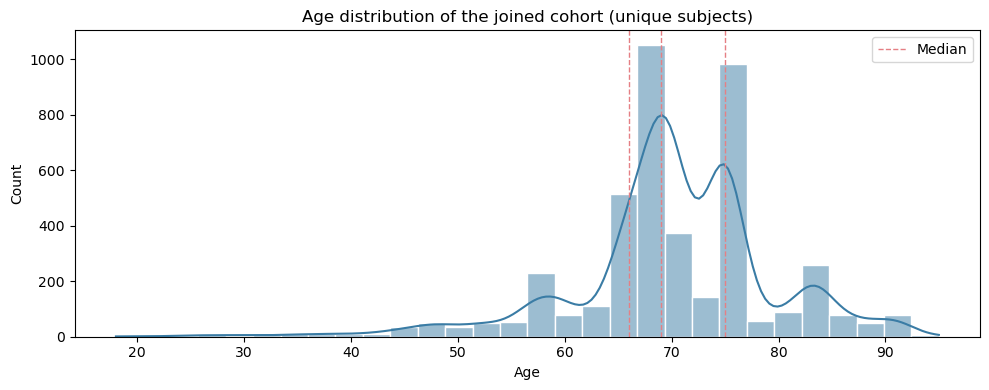

In [ ]:
# Age distribution with KDE overlay and highlighted quartiles (unique subjects)
unique_subject_age = (
    joined_df[['subject_id', 'age']]
    .dropna(subset=['age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 4))
sns.histplot(
    data=unique_subject_age,
    x='age',
    bins=30,
    kde=True,
    color='#3A7CA5',
    edgecolor='white'
)
q1, q2, q3 = unique_subject_age['age'].quantile([0.25, 0.5, 0.75])
for q, label in zip([q1, q2, q3], ['Q1', 'Median', 'Q3']):
    plt.axvline(q, color='#E57F84', linestyle='--', linewidth=1, label=label if label == 'Median' else None)
plt.title('Age distribution of the joined cohort (unique subjects)')
plt.xlabel('Age')
plt.ylabel('Count')
plt.legend(loc='upper right')
plt.tight_layout()

## Sex distribution per ICD code

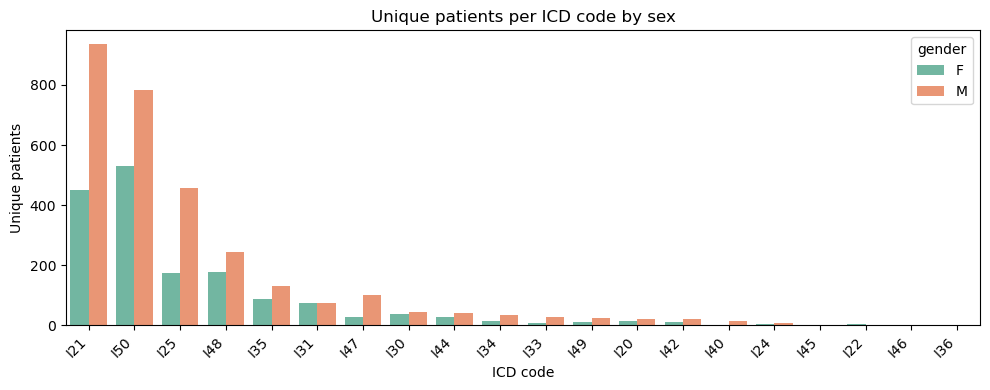

In [ ]:
counts = (
    joined_df.groupby(['icd_code_joined', 'gender'])['subject_id']
    .nunique()
    .reset_index(name='unique_patients')
)

icd_order = (
    counts.groupby('icd_code_joined')['unique_patients']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=counts,
    x='icd_code_joined',
    y='unique_patients',
    hue='gender',
    palette='Set2',
    order=icd_order
)
plt.title('Unique patients per ICD code by sex')
plt.xlabel('ICD code')
plt.ylabel('Unique patients')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

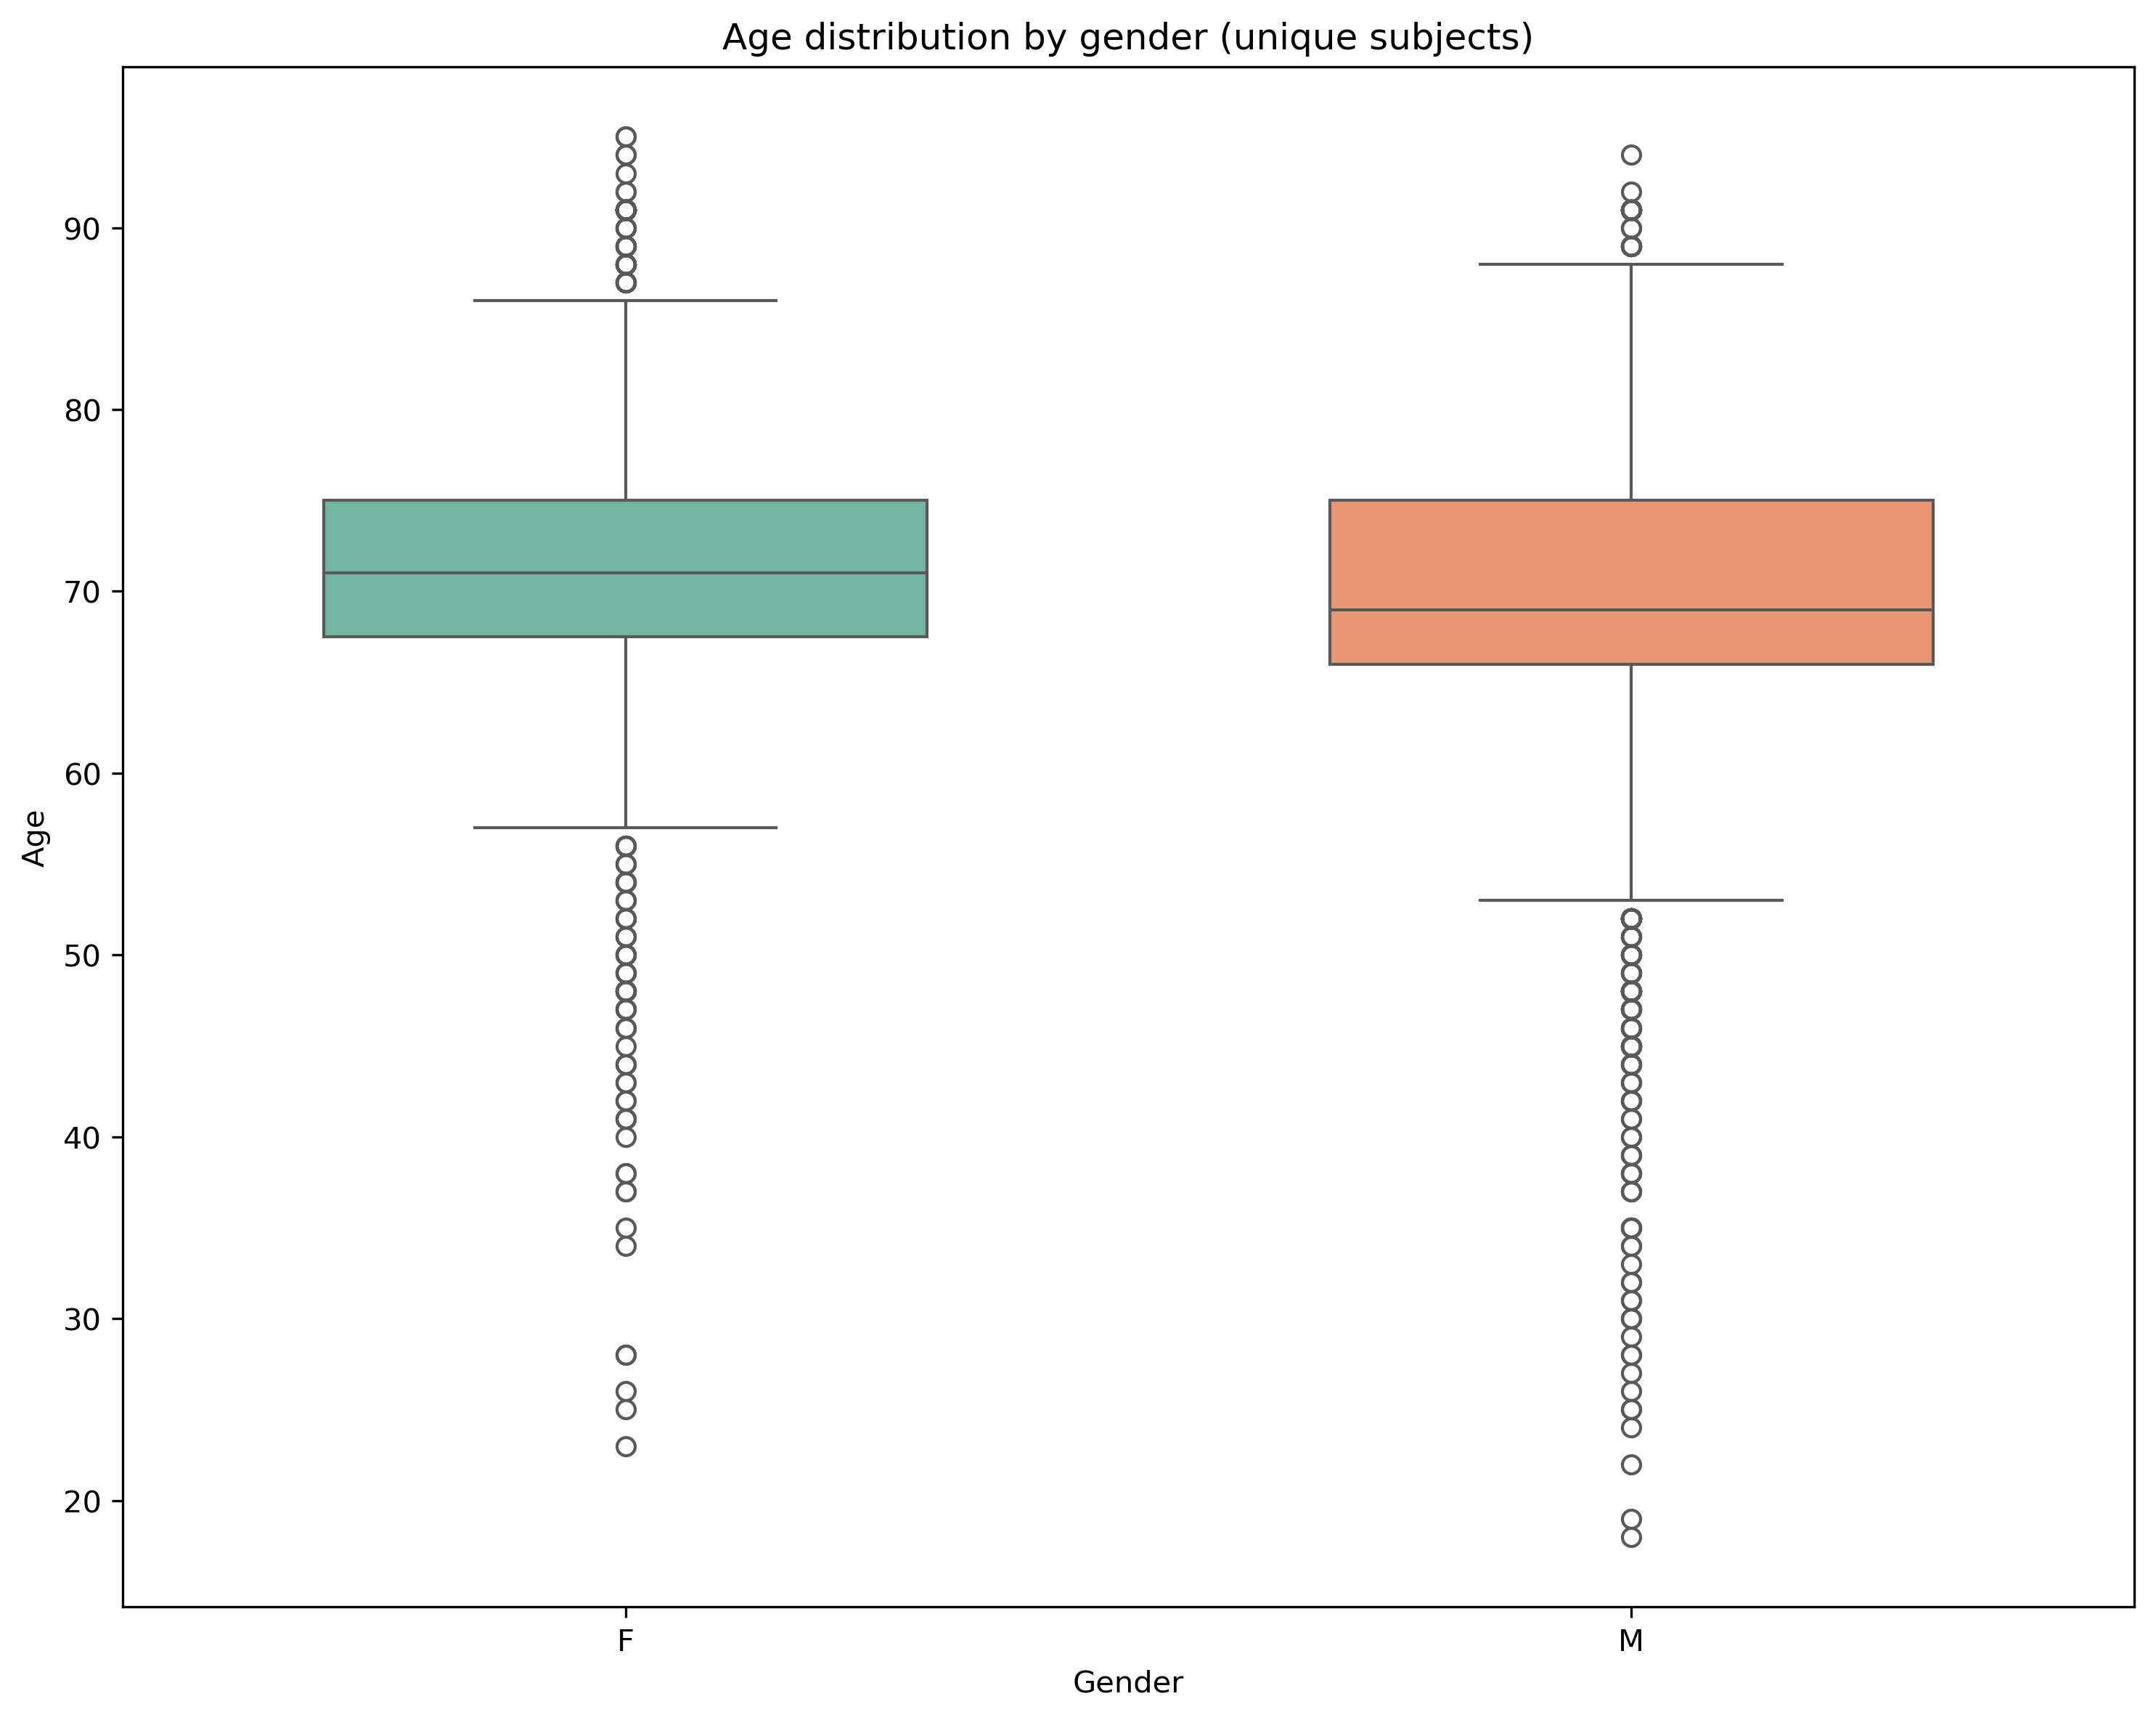

In [ ]:
subject_age = (
    joined_df[['subject_id', 'gender', 'age']]
    .dropna(subset=['gender', 'age'])
    .drop_duplicates(subset='subject_id')
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=subject_age,
    x='gender',
    y='age',
    hue='gender',
    palette='Set2',
    width=0.6,
    dodge=False,
    legend=False
)
plt.title('Age distribution by gender (unique subjects)')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.tight_layout()

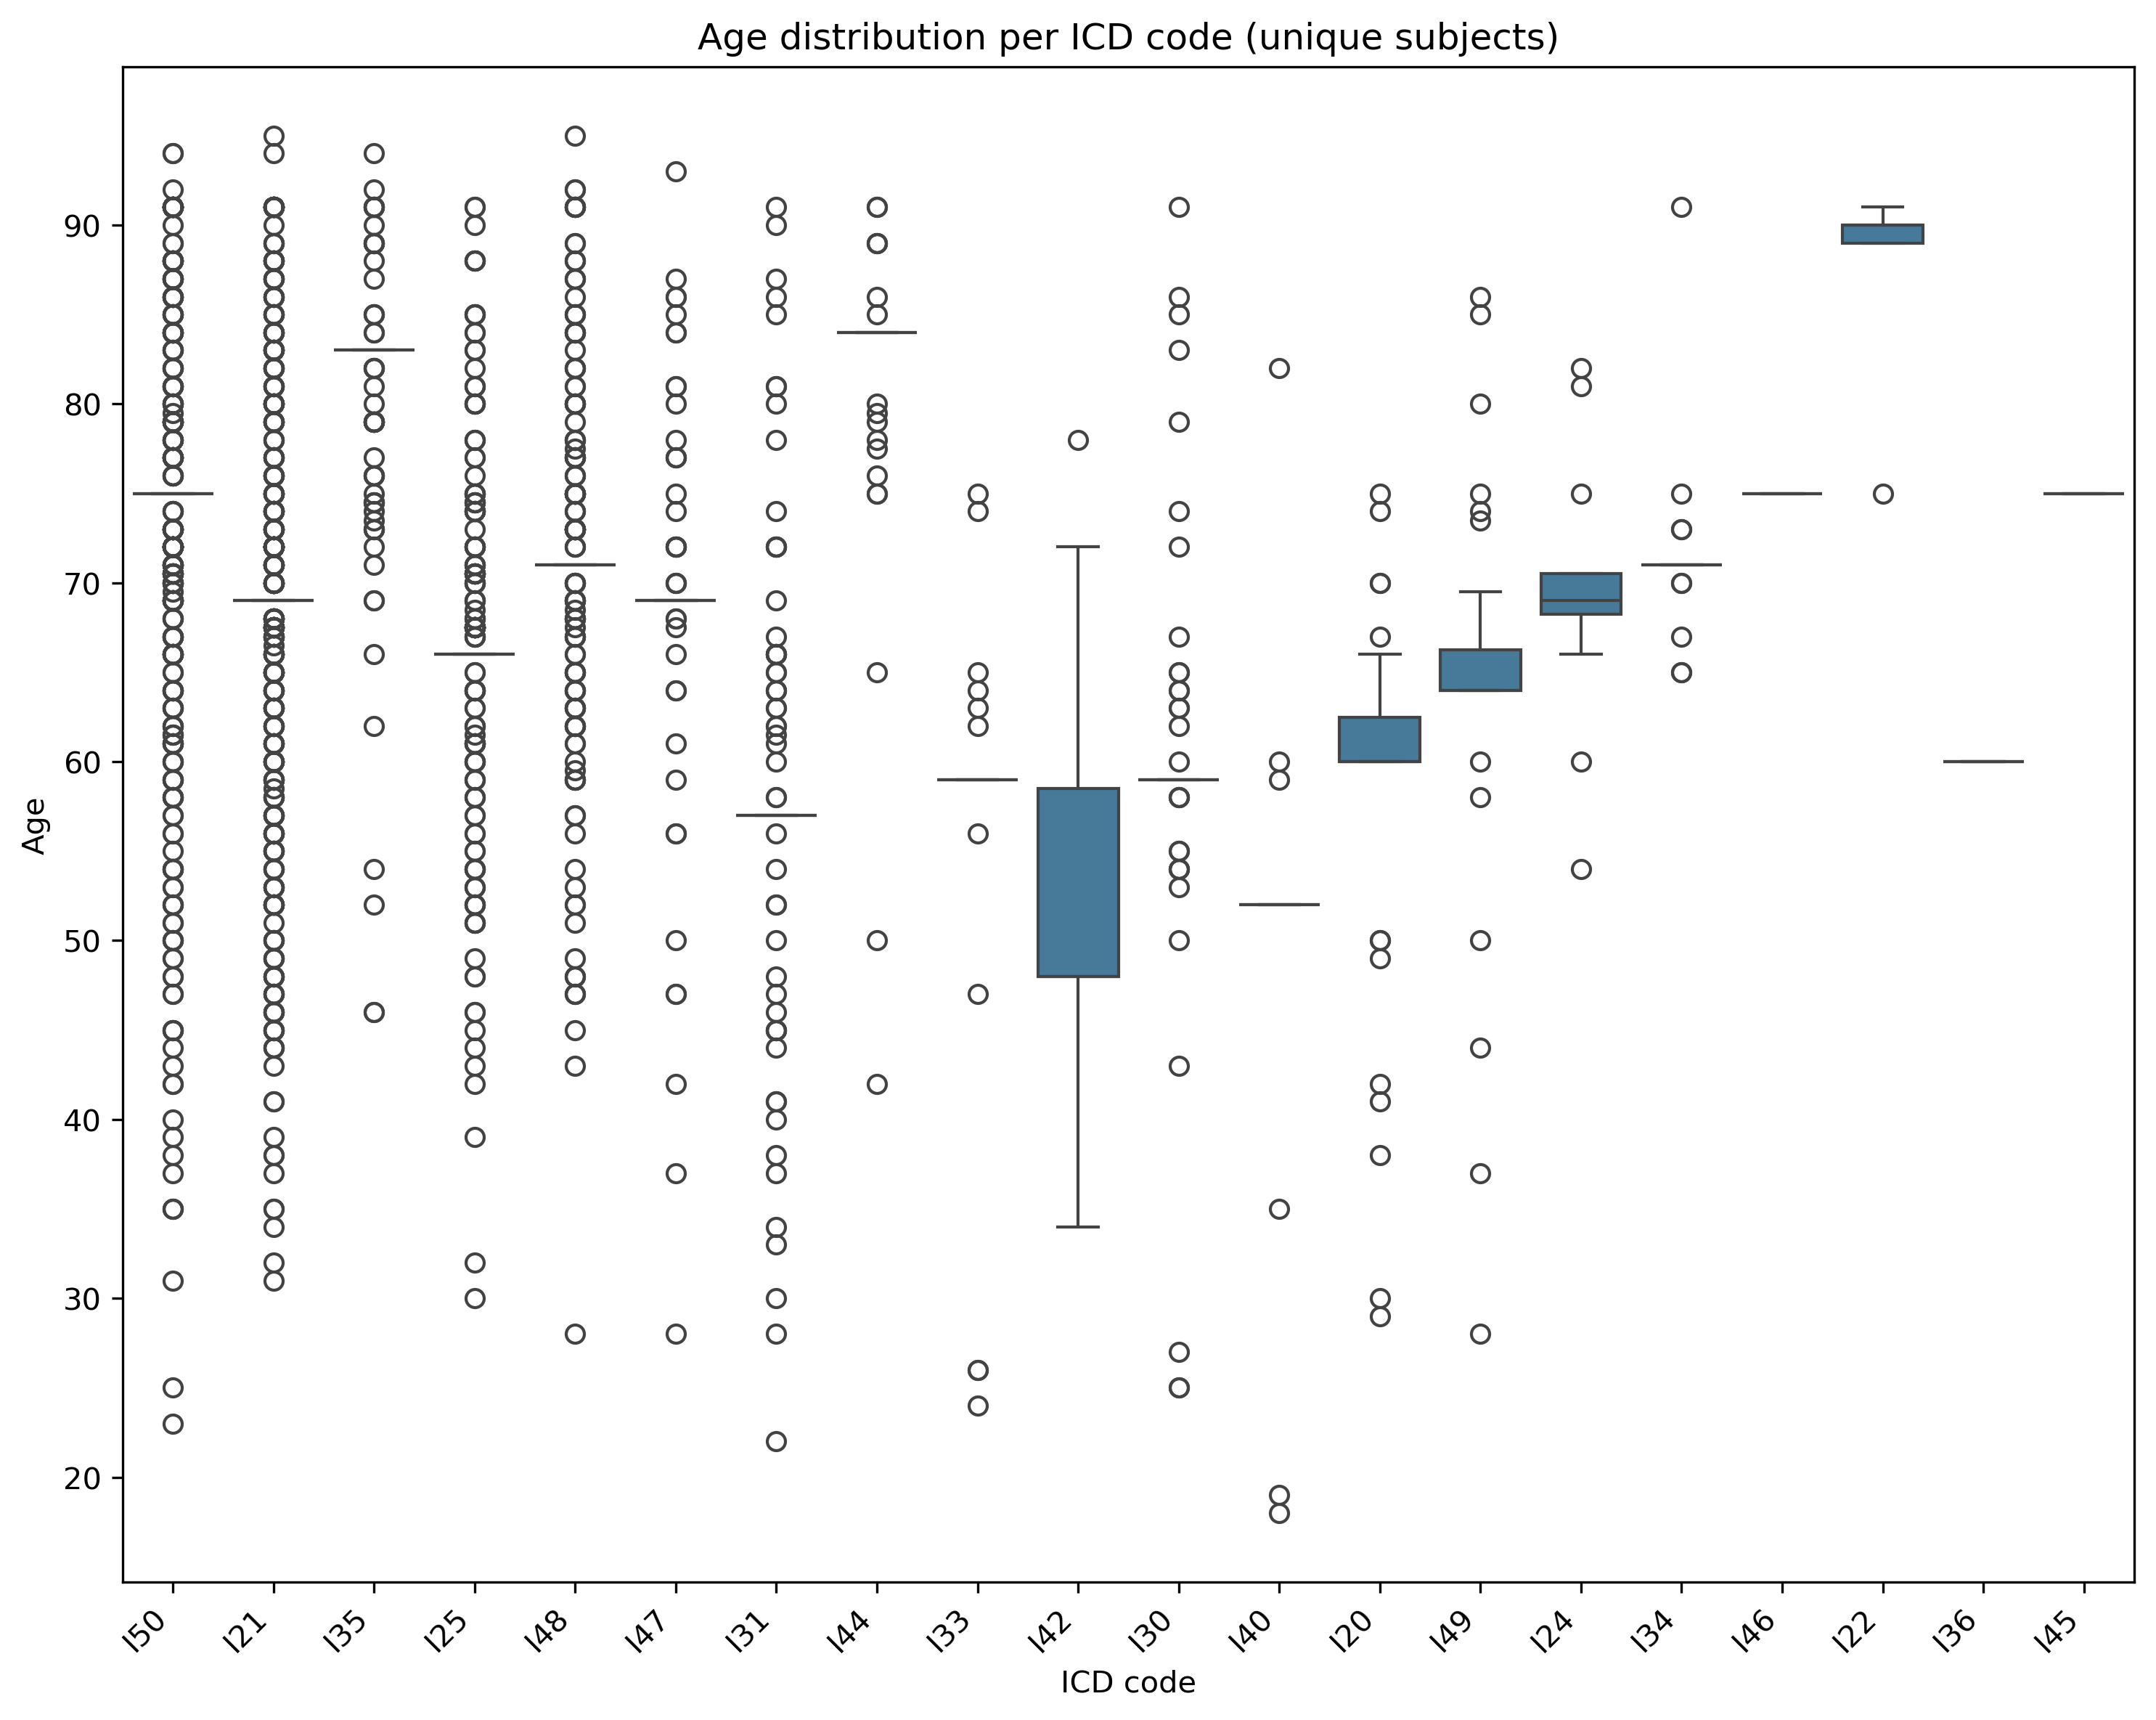

In [ ]:
#to visualize for each icd_code the age of the patient 
icd_age = (
    joined_df[['subject_id', 'icd_code_joined', 'age']]
    .dropna(subset=['icd_code_joined', 'age'])
    .drop_duplicates(subset=['subject_id', 'icd_code_joined'])
)

plt.figure(figsize=(10, 8), dpi=300)
sns.boxplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    color='#3A7CA5'
)
plt.title('Age distribution per ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

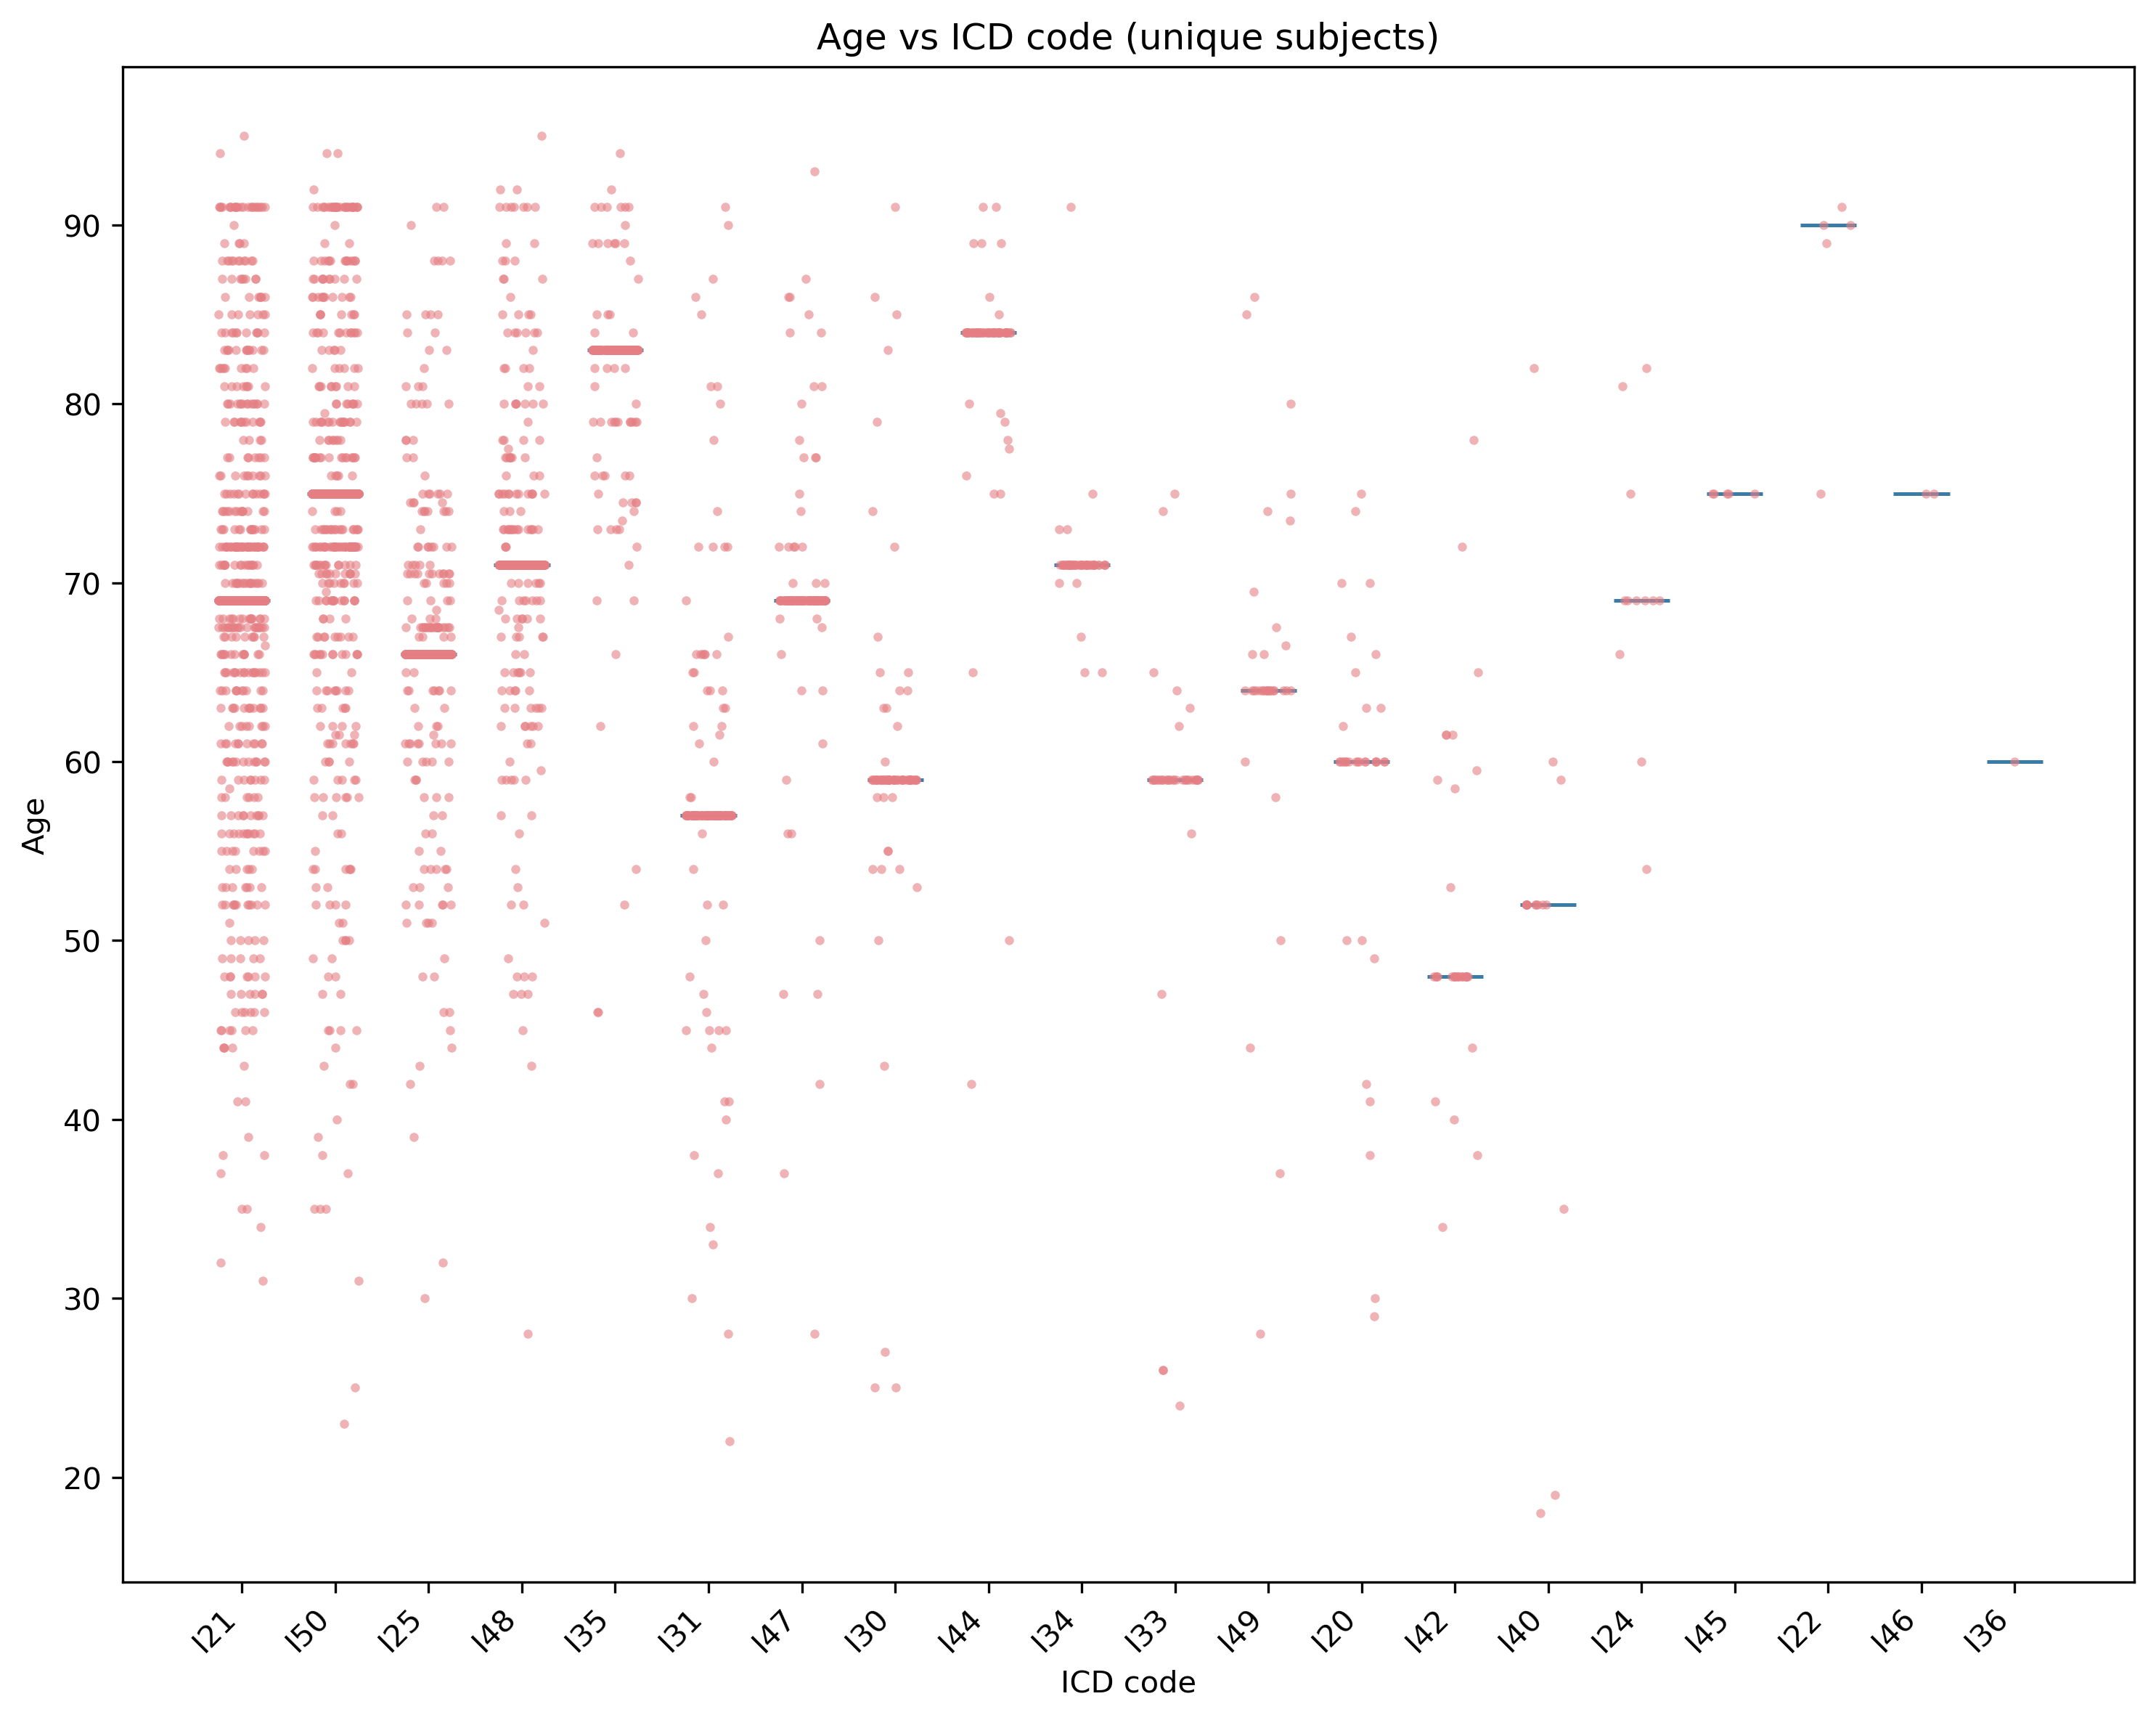

In [ ]:
icd_order = (
    icd_age.groupby('icd_code_joined')['subject_id']
    .nunique()
    .sort_values(ascending=False)
    .index
)

median_age_by_icd = (
    icd_age.groupby('icd_code_joined')['age']
    .median()
    .reindex(icd_order)
)

plt.figure(figsize=(10, 8), dpi=300)
sns.stripplot(
    data=icd_age,
    x='icd_code_joined',
    y='age',
    order=icd_order,
    color='#E57F84',
    jitter=0.25,
    size=3,
    alpha=0.6
)

for idx, age in enumerate(median_age_by_icd):
    plt.hlines(age, idx - 0.3, idx + 0.3, color='#3A7CA5', linewidth=1.2)

plt.title('Age vs ICD code (unique subjects)')
plt.xlabel('ICD code')
plt.ylabel('Age')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

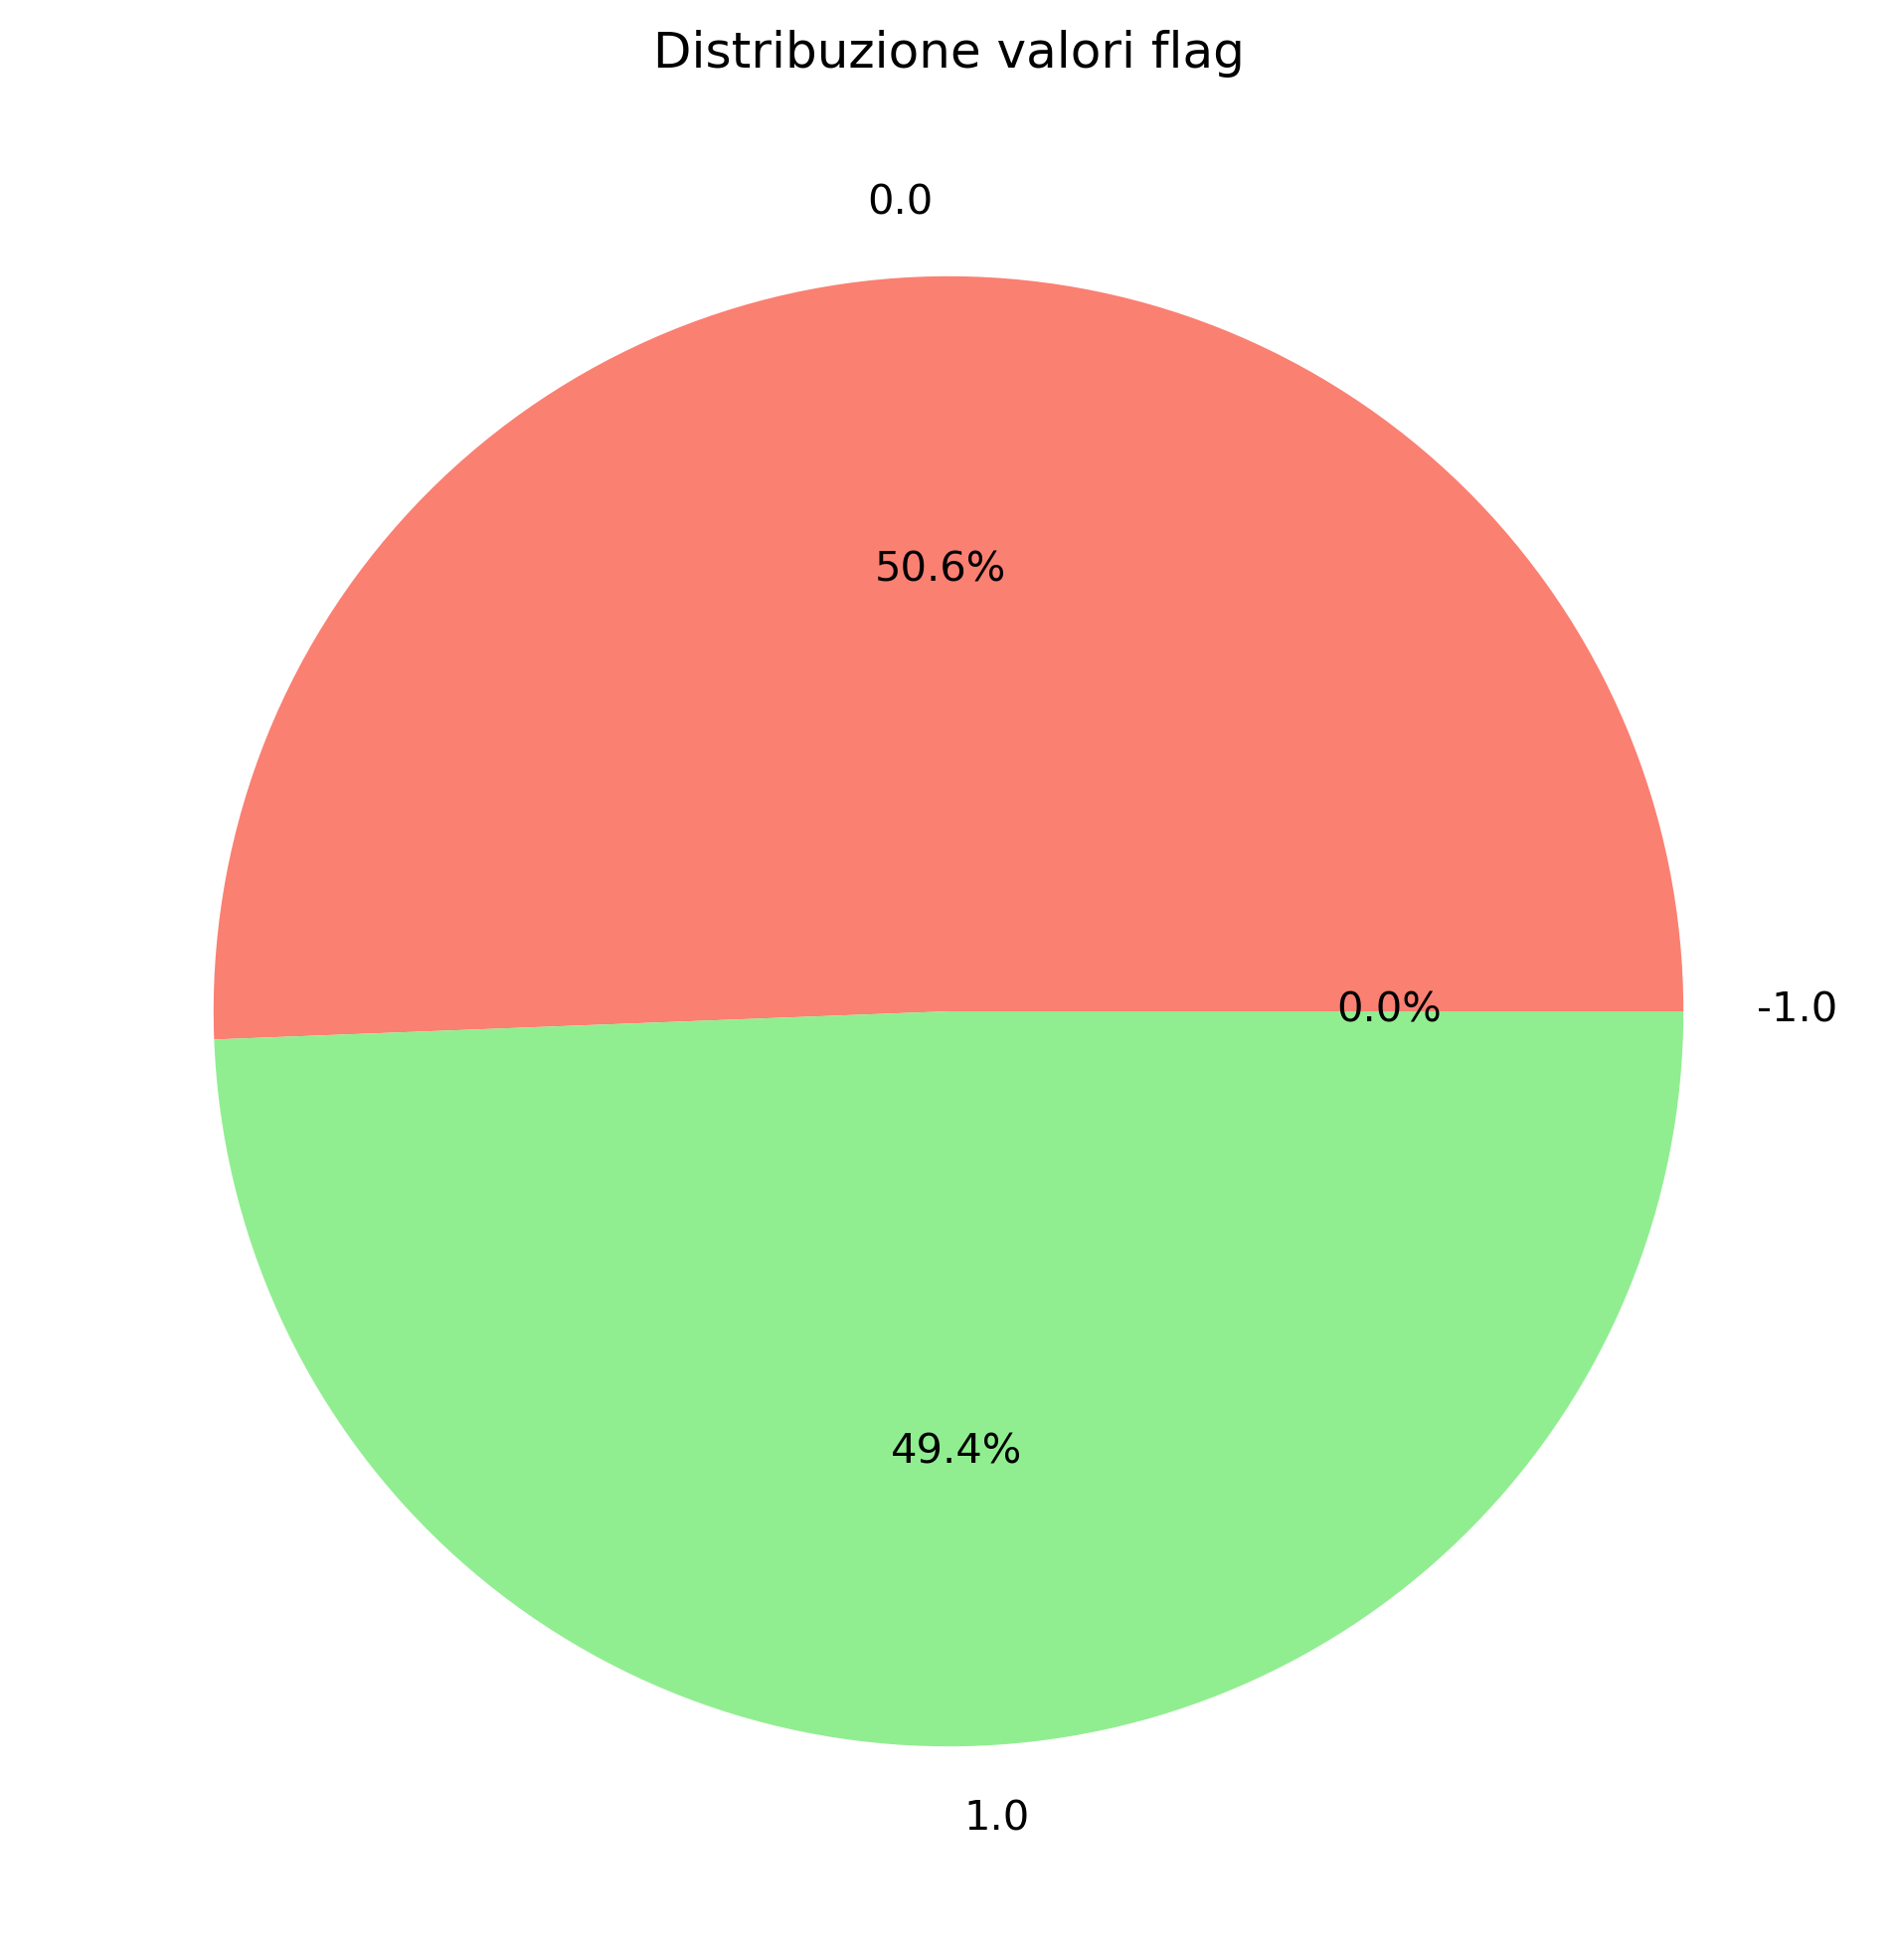

In [ ]:
# Prima conta i valori della colonna flag
counts = joined_df['flag'].value_counts().sort_index()

# Poi crea il grafico a torta
plt.figure(figsize=(10, 8), dpi=300)
plt.pie(counts.values, 
        labels=counts.index,  # oppure ['Normale', 'Anormale']
        autopct='%1.1f%%',
        colors=['lightgreen', 'salmon'])
plt.title('Distribuzione valori flag')
plt.show()

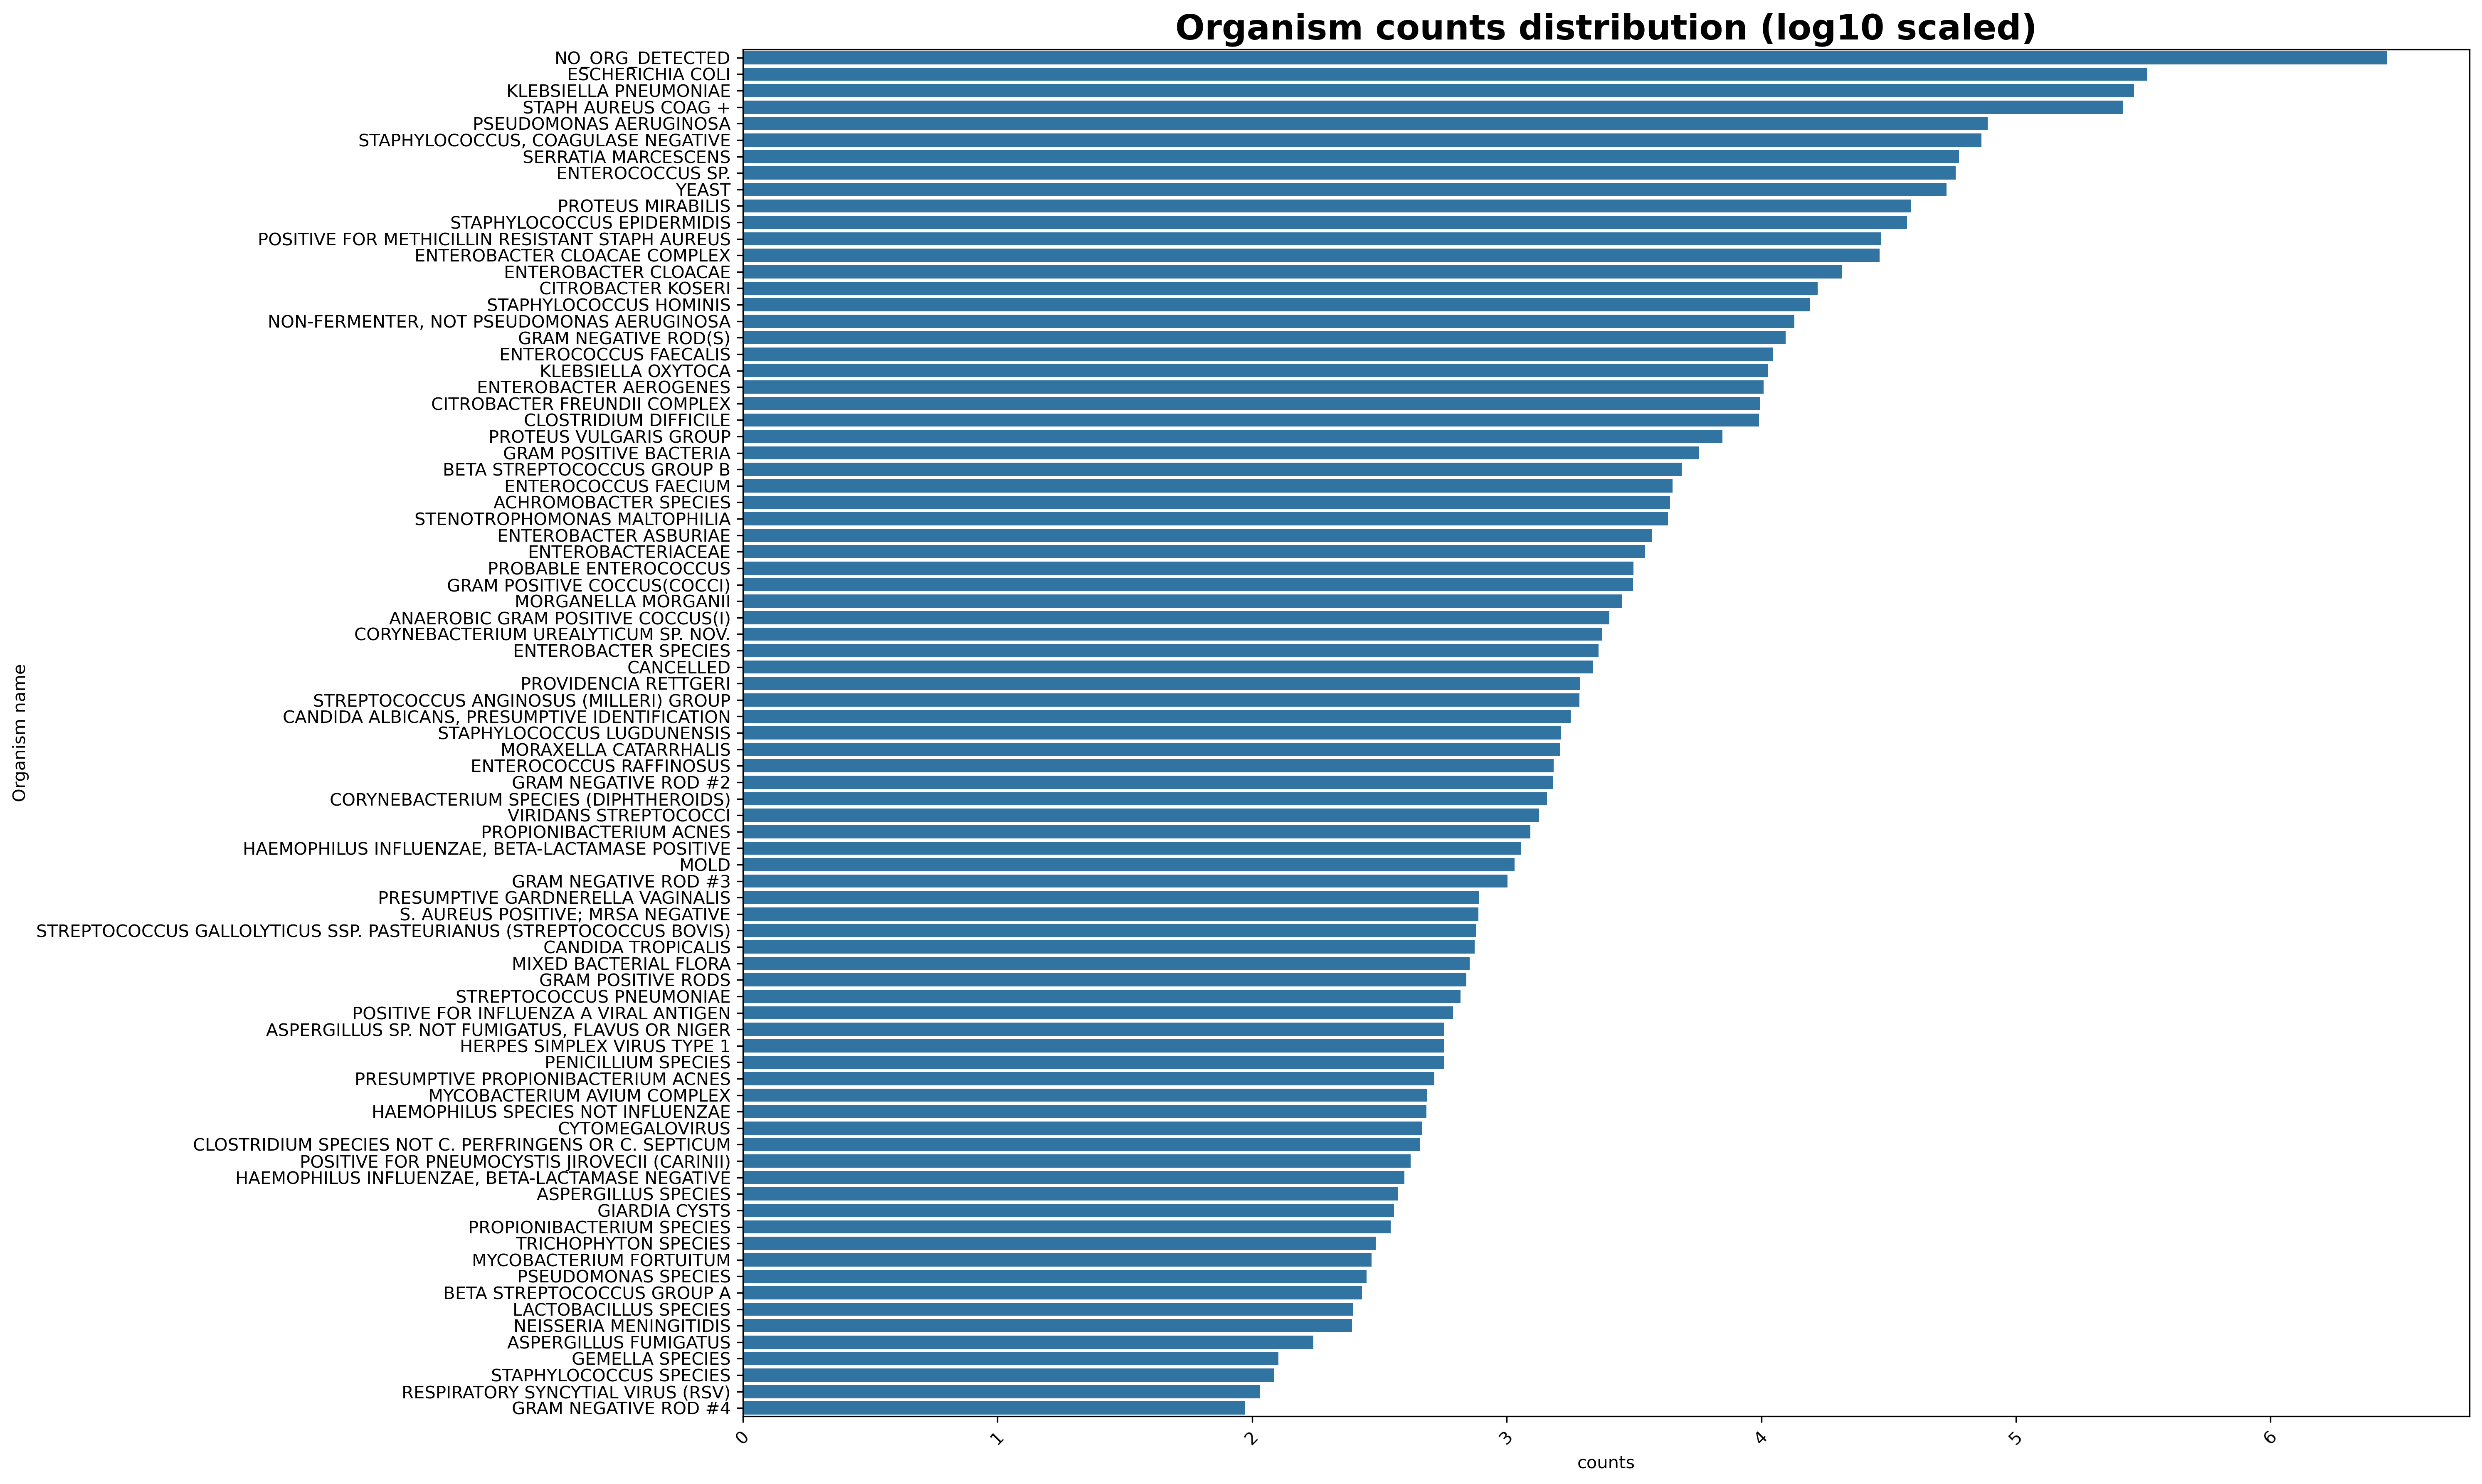

In [ ]:
org_count = np.log10(joined_df['org_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(y=org_count.index, x=org_count.values)
plt.title("Organism counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Organism name")
plt.xlabel("counts")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

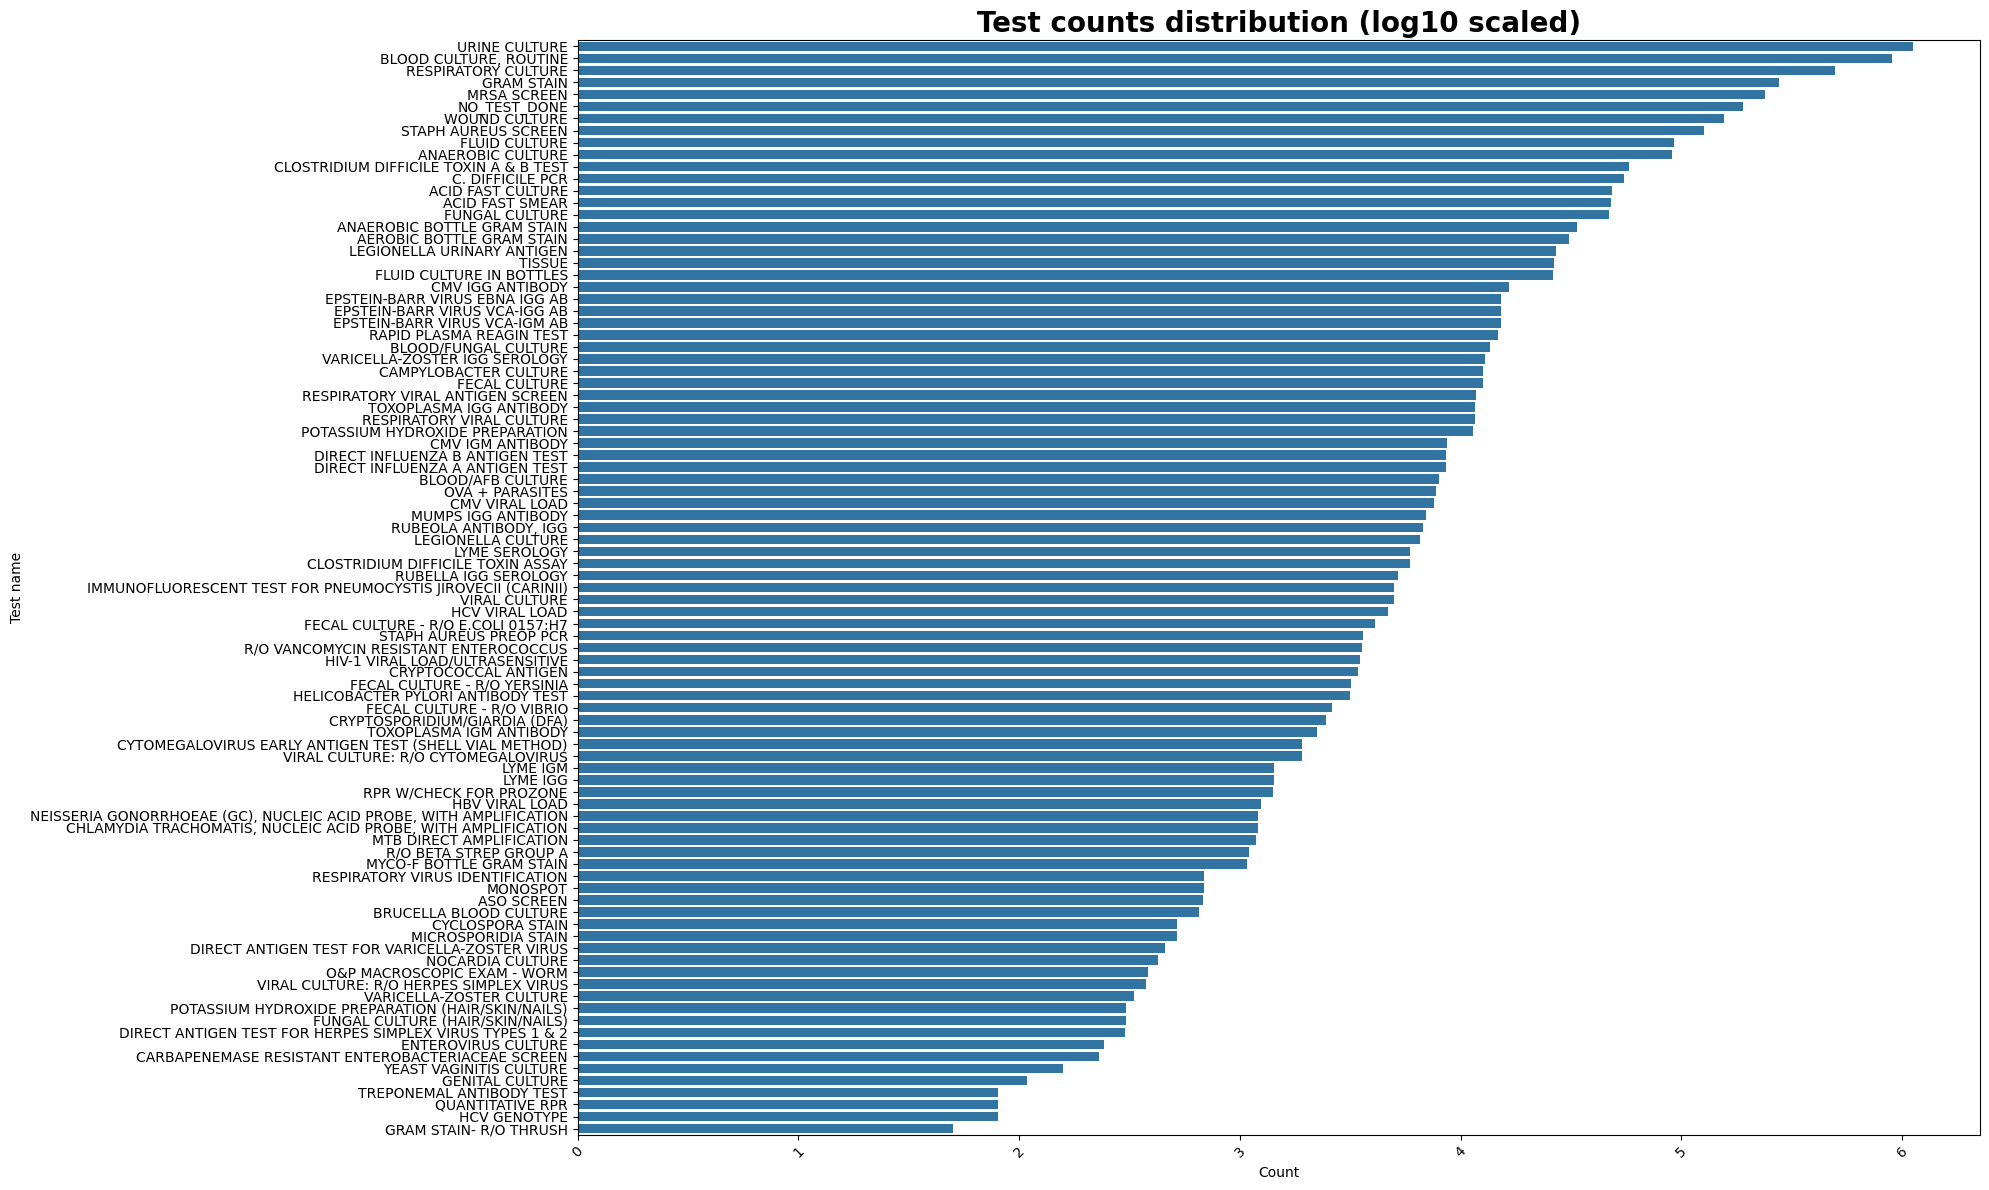

In [ ]:
test_count = np.log10(joined_df['test_name'].value_counts().replace(0, np.nan))

plt.figure(figsize=(20, 12))
sns.barplot(y=test_count.index, x=test_count.values)
plt.title("Test counts distribution (log10 scaled)", fontsize=20, fontweight="bold")
plt.ylabel("Test name")
plt.xlabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

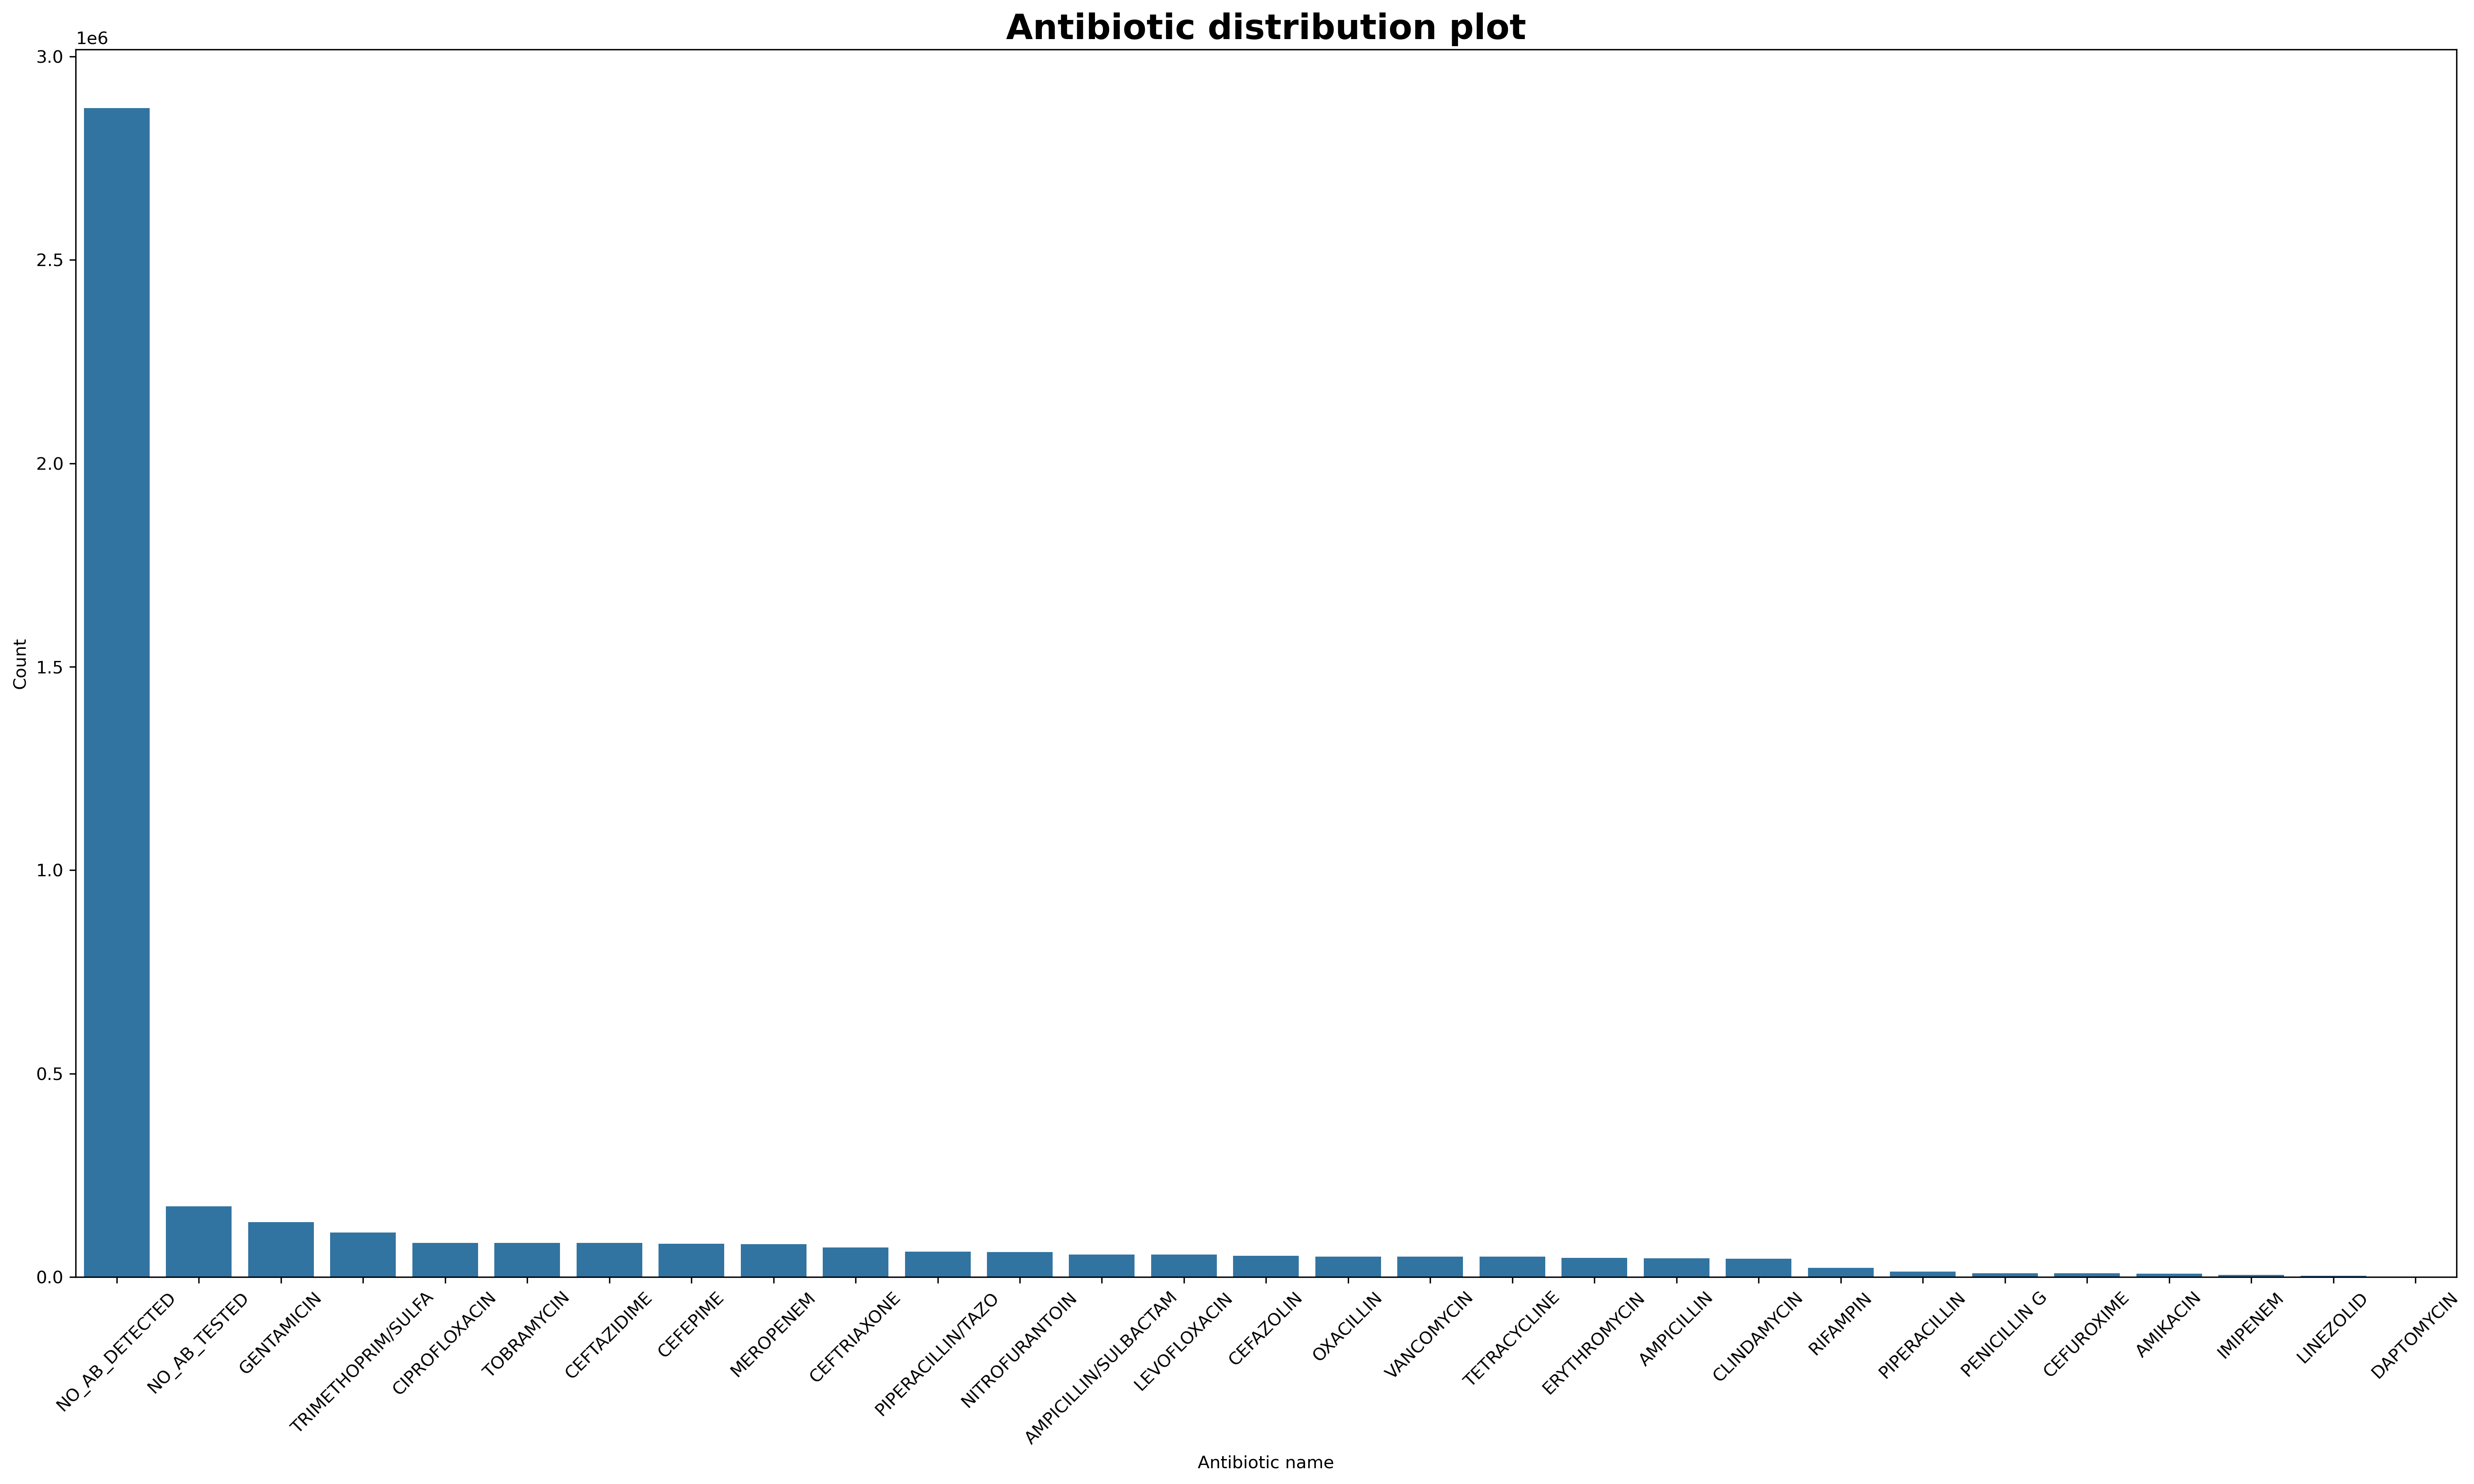

In [ ]:
ab_count =joined_df['ab_name'].value_counts()

plt.figure(figsize=(20, 12), dpi=300)
sns.barplot(x=ab_count.index, y=ab_count.values)
plt.title("Antibiotic distribution plot", fontsize=20, fontweight="bold")
plt.xlabel("Antibiotic name")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

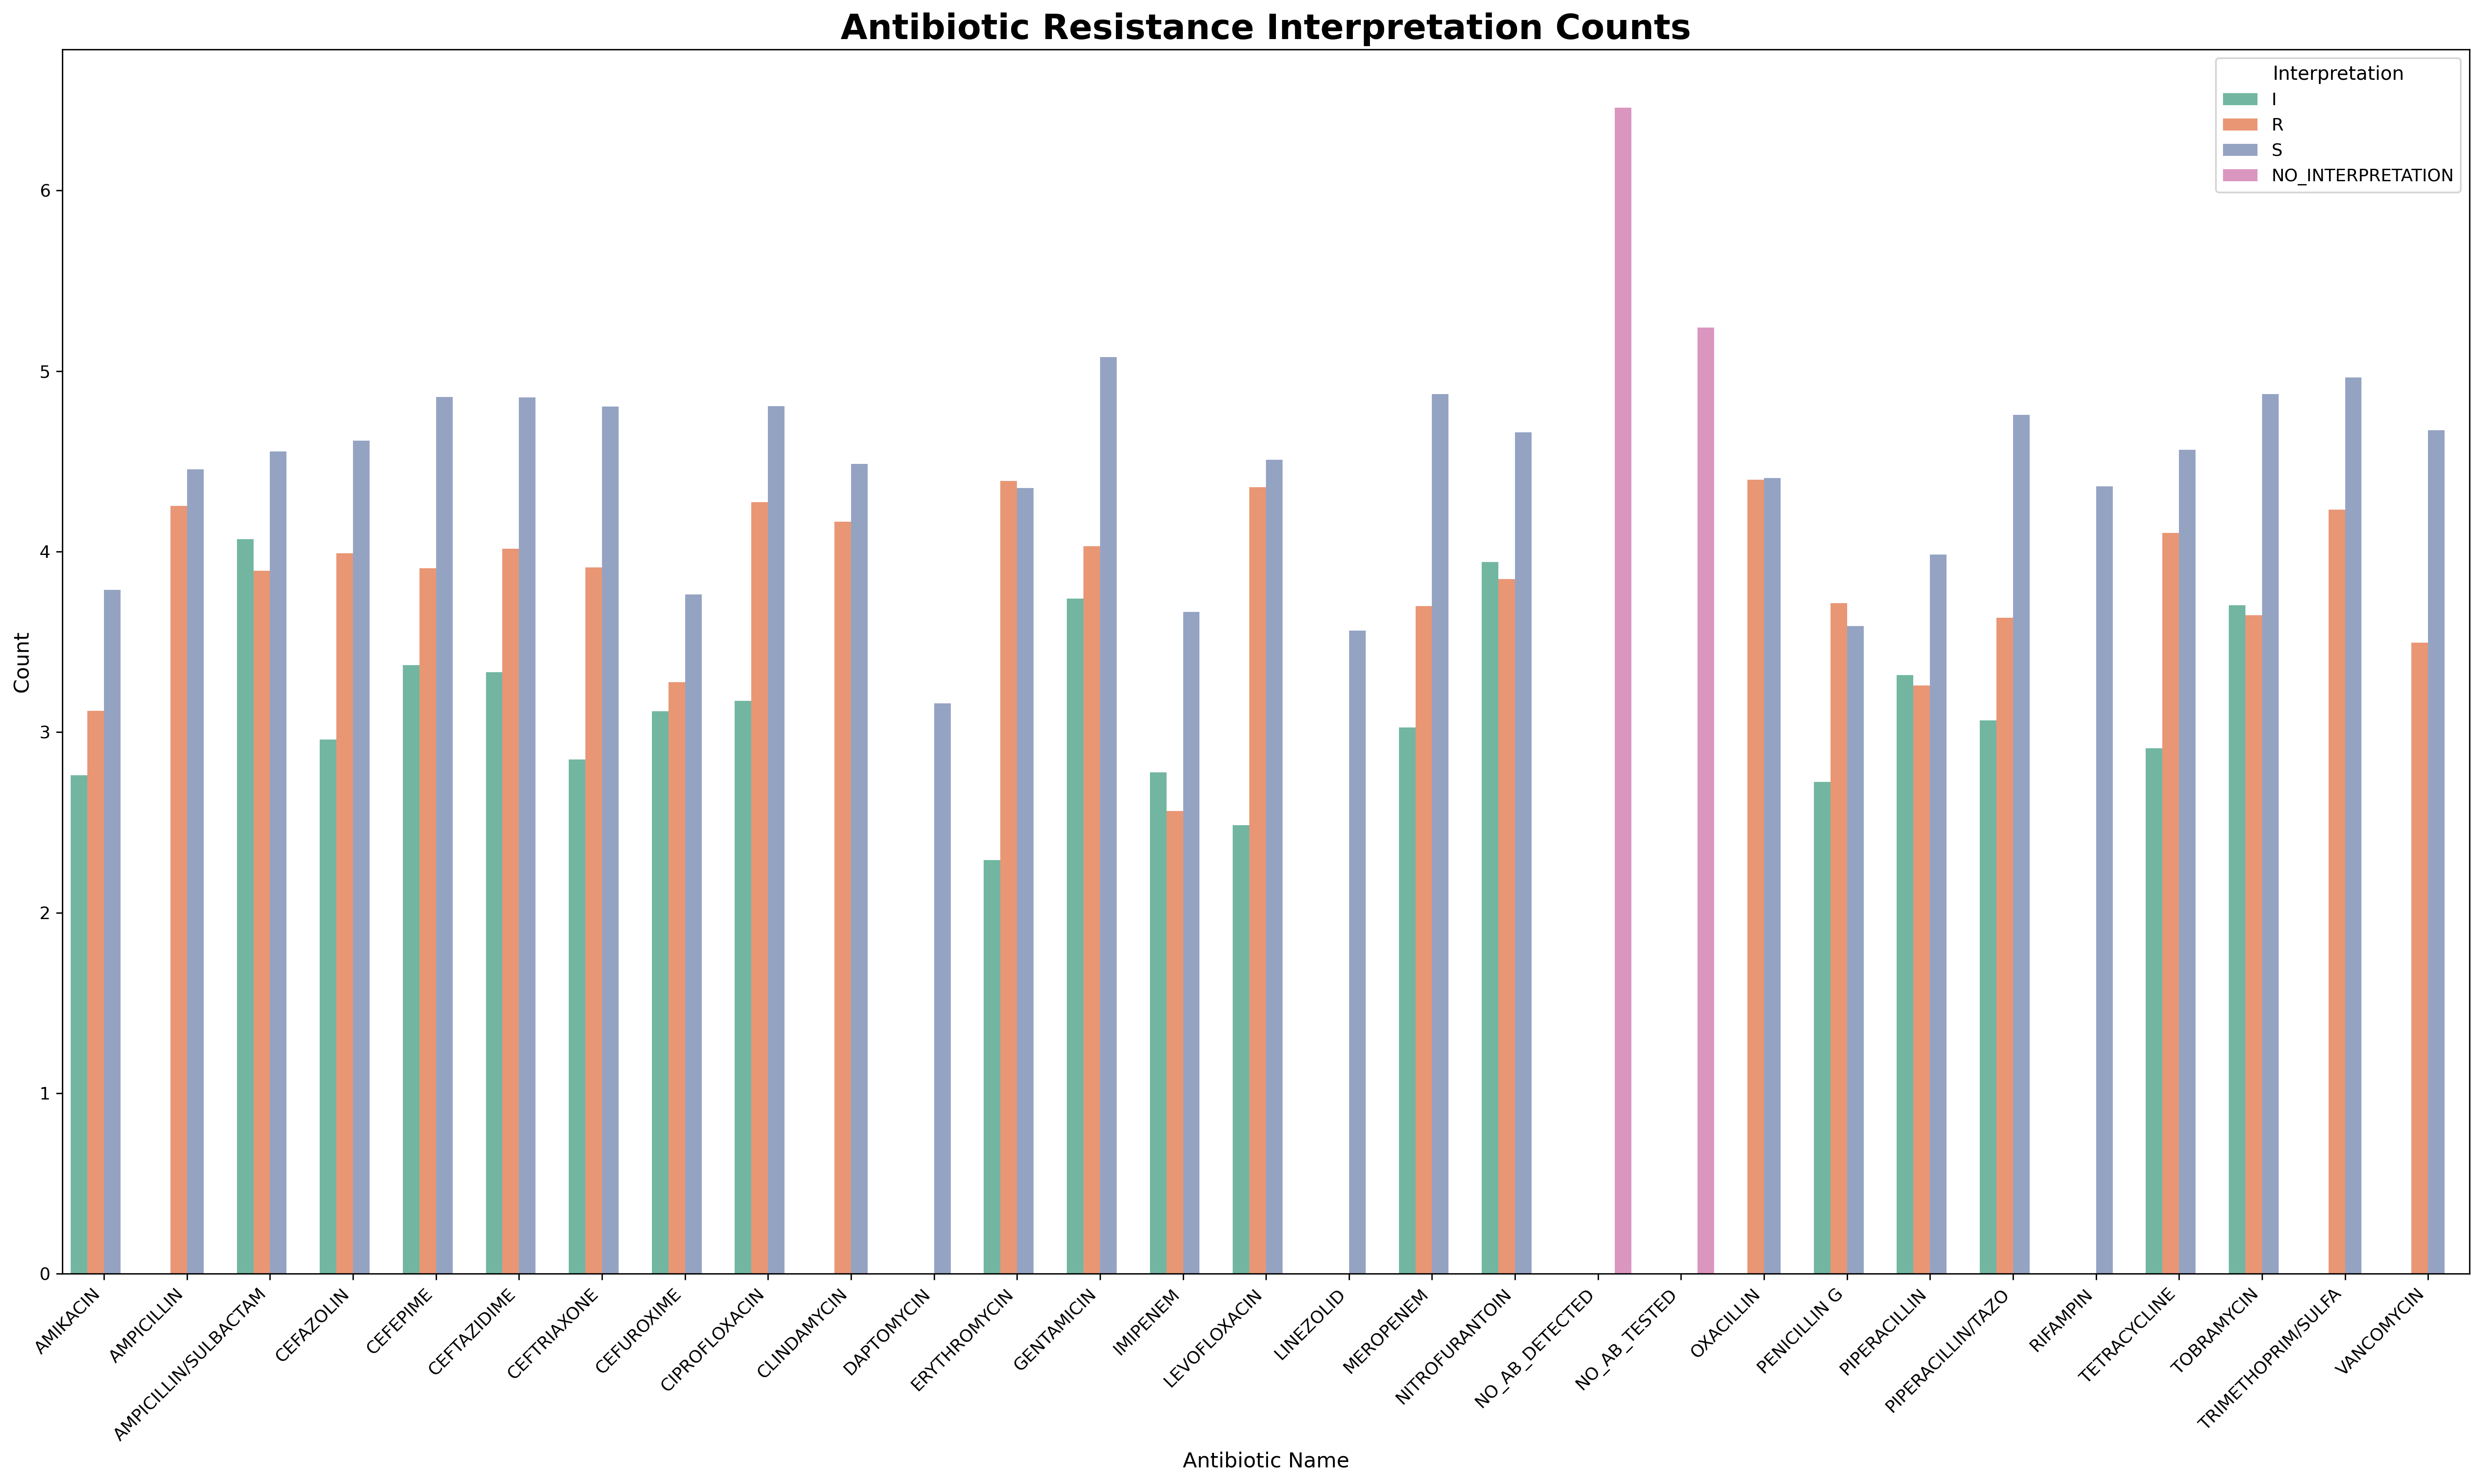

In [ ]:
# Get the counts
resistant_counts = np.log10(joined_df.groupby("ab_name")['interpretation'].value_counts().replace(0, np.nan))
counts_df = resistant_counts.reset_index(name='count')

# Calculate average count for each interpretation to determine order
interpretation_avg = counts_df.groupby('interpretation')['count'].mean().sort_values(ascending=True)
sorted_interpretations = interpretation_avg.index.tolist()

# Create the plot
fig, ax = plt.subplots(figsize=(20,12), dpi=300)

# Create grouped barplot with sorted hue order
sns.barplot(
    data=counts_df,
    x='ab_name',
    y='count',
    hue='interpretation',
    ax=ax,
    palette='Set2',
    hue_order=sorted_interpretations
)

# Customize the plot
ax.set_title('Antibiotic Resistance Interpretation Counts', fontsize=20, fontweight='bold')
ax.set_xlabel('Antibiotic Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.legend(title='Interpretation', title_fontsize=11, fontsize=10)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

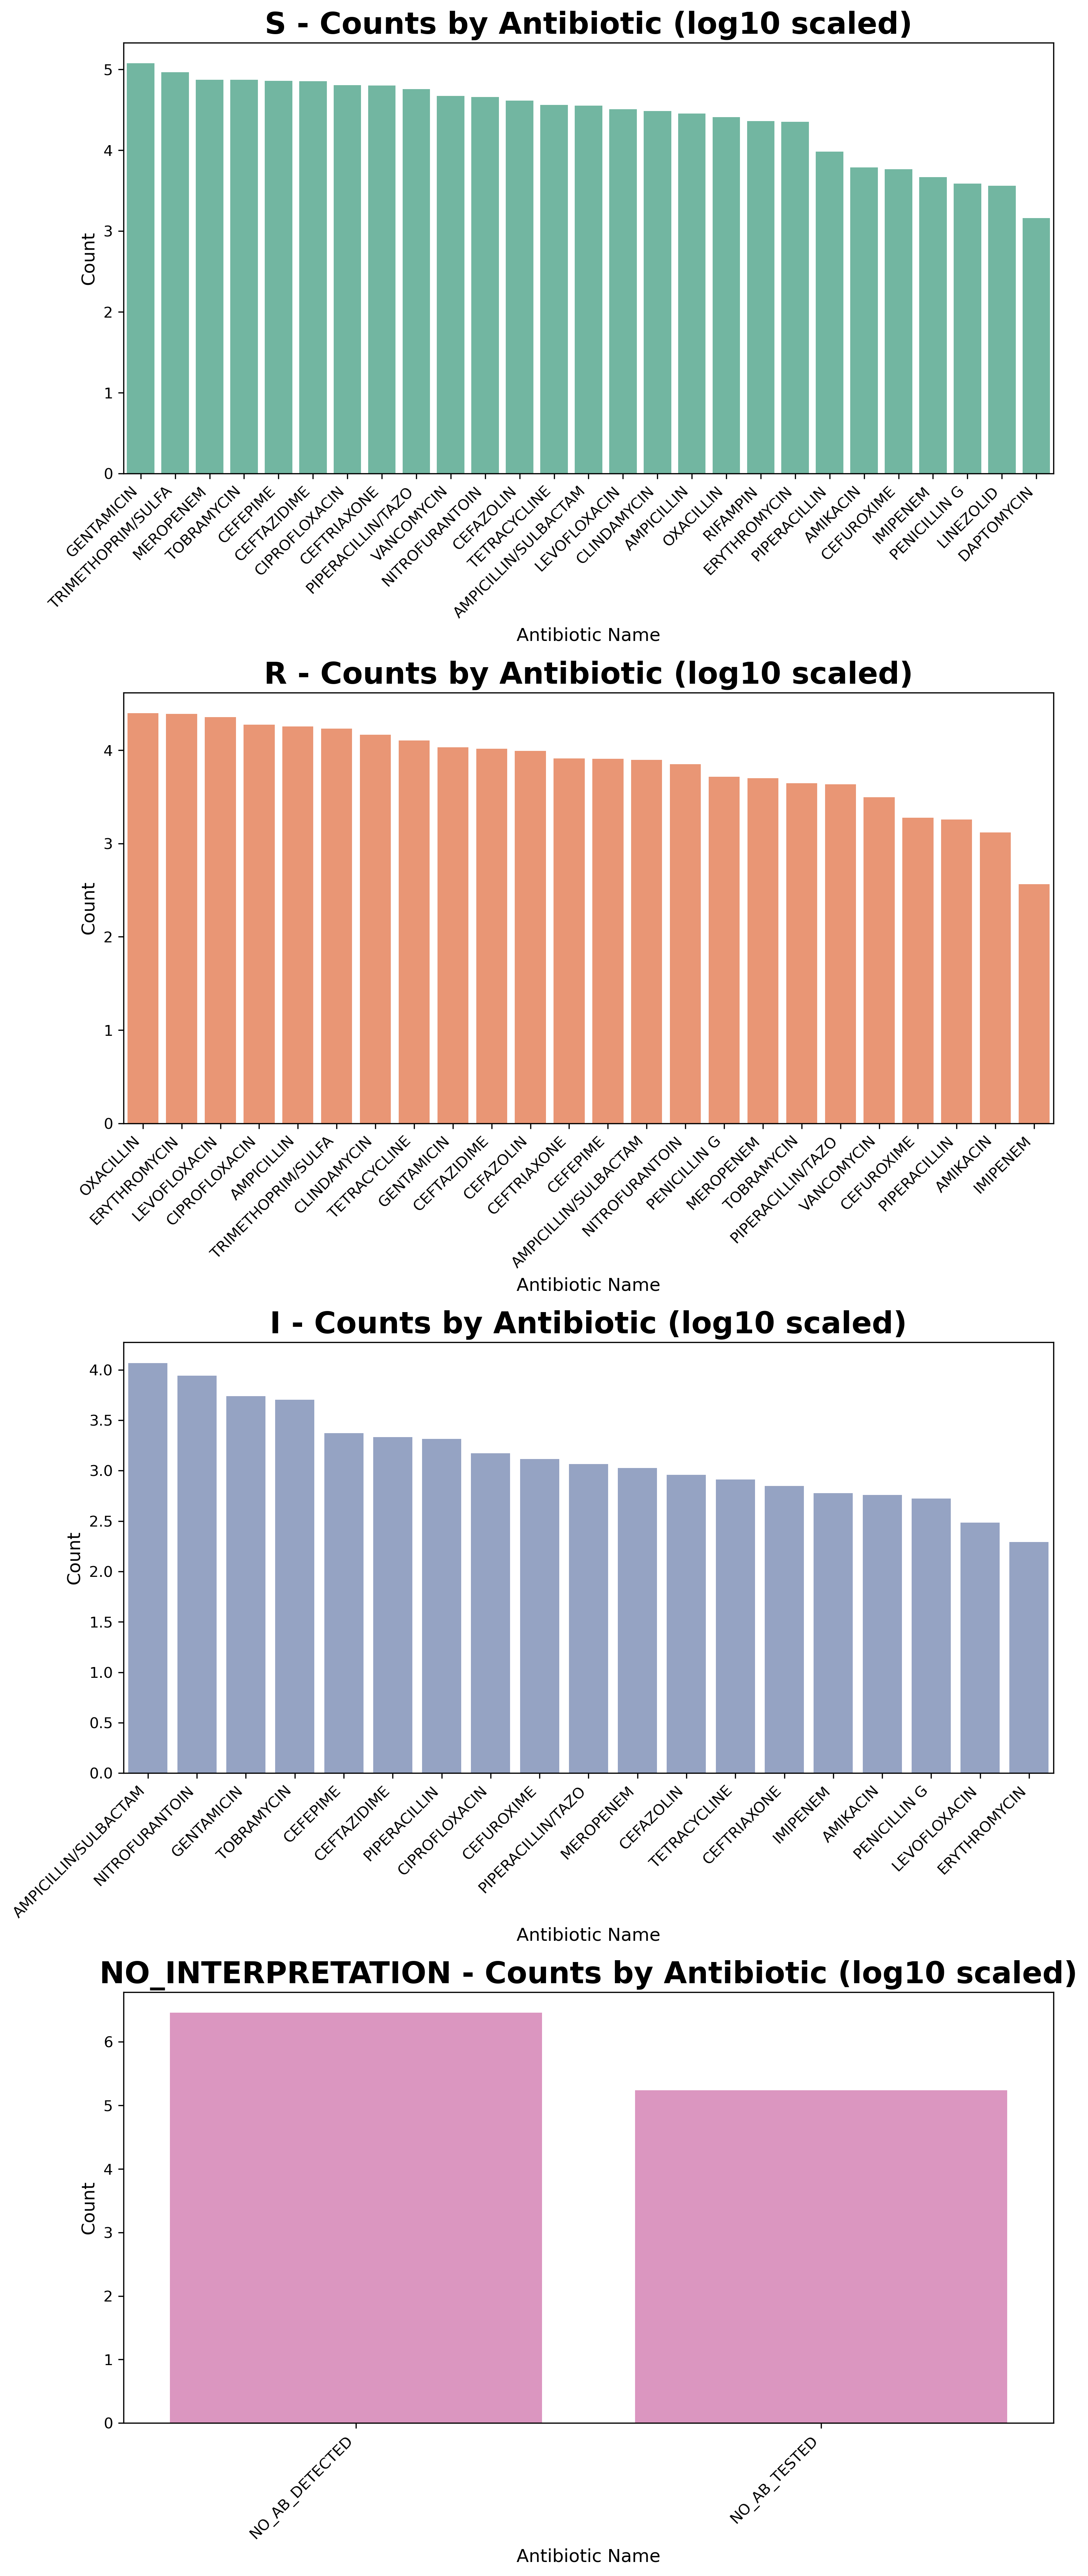

In [ ]:
# Get unique interpretations
interpretations = counts_df['interpretation'].unique()
n_interpretations = len(interpretations)

# Create subplots - one for each interpretation
fig, axes = plt.subplots(n_interpretations, 1, figsize=(10,  6* n_interpretations), dpi=300)

# Handle case of single interpretation
if n_interpretations == 1:
    axes = [axes]

# Create a plot for each interpretation
for idx, interpretation in enumerate(interpretations):
    # Filter data for this interpretation
    subset = counts_df[counts_df['interpretation'] == interpretation]
    
    # Sort by count in descending order
    subset = subset.sort_values('count', ascending=False)
    
    # Create barplot
    sns.barplot(
        data=subset,
        x='ab_name',
        y='count',
        ax=axes[idx],
        color=sns.color_palette('Set2')[idx % 10],
        order=subset['ab_name']  # Explicitly set the order
    )
    
    # Customize the subplot
    axes[idx].set_title(f'{interpretation} - Counts by Antibiotic (log10 scaled)', 
                        fontsize=20, fontweight='bold')
    axes[idx].set_xlabel('Antibiotic Name', fontsize=12)
    axes[idx].set_ylabel('Count', fontsize=12)
    
    # Rotate x-axis labels
    axes[idx].tick_params(axis='x', rotation=45)
    plt.setp(axes[idx].xaxis.get_majorticklabels(), ha='right')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()